# FCA complaints project — data cleaning and combined EDA

**2022 H1–2026 H1 · Complaints opened**

This notebook combines the five supplied notebooks in a reproducible execution order:
1. Shared Google Drive setup and file locations.
2. Aggregate data cleaning and checks.
3. Firm-level data cleaning and checks.
4. Overall trends EDA.
5. Financial-product EDA.
6. Firm-level EDA (9 steps).

**How to run in Google Colab:** open the notebook, set `PROJECT_DIR` in the next code cell to the shared folder **as it appears in your own mounted Google Drive**, and choose whether to rebuild the cleaned CSVs. Then select **Runtime → Run all**.

**For groupmates:** a folder under someone else's **Shared with me** will not automatically appear in `/content/drive/MyDrive/`. In Google Drive, select the shared project folder → **Organize → Add shortcut** → **My Drive**. Give the shortcut the expected name (or adjust `PROJECT_DIR`). Everyone can then use the same folder-relative filenames, even with different personal notebook locations. **Viewer access is enough for analysis**; editing access is needed if you choose to overwrite cleaned data.

The shared data are **read from Drive paths**, not `gdown` URLs or paths relative to the notebook's working directory. The notebook preserves the original analysis methods and intentionally **does not replace missing complaint counts with zero**.

## 0. Connect Google Drive and configure shared paths

In [1]:
# Run once at the top of Google Colab. Groupmates only edit PROJECT_DIR if their shortcut differs.
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

drive.mount('/content/drive')

# Shared Google Drive folder (existing path from the aggregate cleaning notebook)
PROJECT_DIR = Path('/content/drive/MyDrive/Project lab dataset')
FIRM_LEVEL_DIR = PROJECT_DIR / 'Firm level data'

AGGREGATE_SOURCE = PROJECT_DIR / 'aggregate-complaints-data-2026-h1.xlsx'
AGGREGATE_CLEAN_CSV = PROJECT_DIR / 'aggregate_filtered_2022H1_2026H1.csv'
FIRM_CLEAN_CSV = FIRM_LEVEL_DIR / 'firm_level_opened_2022H1_2026H1.csv'

SEMESTER_ORDER = [f'{year} H{half}' for year in range(2022, 2027)
                  for half in (1, 2) if (year, half) <= (2026, 1)]

# False = read the two already-cleaned CSVs (best for teammates / view-only access).
# True  = re-run both original cleaning workflows from the Excel workbooks and
#         overwrite the two cleaned CSVs in the shared Drive folder (editor access required).
REBUILD_CLEANED_DATA = False

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f'Shared project folder not found: {PROJECT_DIR}\n'
        'Add the shared folder shortcut to My Drive or update PROJECT_DIR above.'
    )
if REBUILD_CLEANED_DATA:
    if not AGGREGATE_SOURCE.is_file():
        raise FileNotFoundError(f'Aggregate source workbook not found: {AGGREGATE_SOURCE}')
    if not FIRM_LEVEL_DIR.is_dir():
        raise FileNotFoundError(f'Firm-level workbook folder not found: {FIRM_LEVEL_DIR}')
else:
    missing = [str(p) for p in (AGGREGATE_CLEAN_CSV, FIRM_CLEAN_CSV) if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            'Cleaned CSV(s) not found in the shared folder: ' + ', '.join(missing)
            + '\nAsk the dataset owner to generate/upload them, or set REBUILD_CLEANED_DATA = True '
              'if you have the Excel source files and write access.'
        )

print('Project folder:', PROJECT_DIR)
print('Data mode:', 'REBUILD from Excel' if REBUILD_CLEANED_DATA else 'READ shared cleaned CSVs')
print('Expected semesters:', ', '.join(SEMESTER_ORDER))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Project lab dataset
Data mode: READ shared cleaned CSVs
Expected semesters: 2022 H1, 2022 H2, 2023 H1, 2023 H2, 2024 H1, 2024 H2, 2025 H1, 2025 H2, 2026 H1


# Part A — Clean the aggregate product-specific data

Source: `aggregate_clean-2.ipynb`. The source worksheet is **Product Specific**; the cleaned observations are limited to `Complaints opened` from 2022 H1 through 2026 H1. If `REBUILD_CLEANED_DATA = False`, we load the already-cleaned shared CSV and still run the original data checks.

In [2]:
# Either read the original aggregate Excel workbook, or reuse the cleaned shared CSV.
if REBUILD_CLEANED_DATA:
    df = pd.read_excel(AGGREGATE_SOURCE, sheet_name='Product Specific')
else:
    df = pd.read_csv(AGGREGATE_CLEAN_CSV)

print('Aggregate data loaded:', df.shape)
display(df.head())

Aggregate data loaded: (450, 5)


,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


In [3]:
df.head()

,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


In [4]:
#Examine the dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Semester       450 non-null    object
 1   Product Group  450 non-null    object
 2   Product        450 non-null    object
 3   Variable type  450 non-null    object
 4   Volume         450 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 17.7+ KB


In [5]:
#Summary Statistics for all variables
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Semester,450,9,2022 H1,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Group,450,5,Investments,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,450,50,Credit cards,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Variable type,450,1,Complaints opened,450,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Volume,450.0,NaN,NaN,NaN,36941.075556,85055.596292,0.0,612.0,7457.0,26631.25,541493.0


In [6]:
##Examine each categorical variable individually
#Semester
df["Semester"].value_counts().sort_index()

# Product Group
df["Product Group"].value_counts()

# Product
df["Product"].value_counts()

# Variable type
df["Variable type"].value_counts()

#Volume
df["Volume"].describe()

,Volume
count,450.000000
mean,36941.075556
std,85055.596292
min,0.000000
25%,612.000000
50%,7457.000000
75%,26631.250000
max,541493.000000


In [7]:
#Check for missing values in all variables
df.isna().sum()

,0
Semester,0
Product Group,0
Product,0
Variable type,0
Volume,0


The following checks retain missing values as missing (`NaN`), not zero. The original cleaning logic then selects only opened complaints within the nine-semester window.

Restricting sample to only observations from 2022 H1 to 2026 H1



In [8]:
# Filter by semester AND variable type (same selection as the source cleaning notebook).
df_filtered = df.loc[
    df['Semester'].isin(SEMESTER_ORDER)
    & (df['Variable type'] == 'Complaints opened')
].copy()

print('Filtered aggregate rows:', len(df_filtered))
display(df_filtered.head())

Filtered aggregate rows: 450


,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


In [9]:
# Save only if rebuilding the source data; ordinary EDA users need read access only.
if REBUILD_CLEANED_DATA:
    df_filtered.to_csv(AGGREGATE_CLEAN_CSV, index=False)
    print('Saved cleaned aggregate data to:', AGGREGATE_CLEAN_CSV)
else:
    print('Using existing shared cleaned CSV (no files overwritten):', AGGREGATE_CLEAN_CSV)

Using existing shared cleaned CSV (no files overwritten): /content/drive/MyDrive/Project lab dataset/aggregate_filtered_2022H1_2026H1.csv


In [10]:
#Display the filtered dataset
df_filtered.head()

,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


In [11]:
df_filtered.tail()

,Semester,Product Group,Product,Variable type,Volume
445,2026 H1,Investments,Other investment products/funds,Complaints opened,8971
446,2026 H1,Investments,Platforms,Complaints opened,12874
447,2026 H1,Investments,Structured products,Complaints opened,319
448,2026 H1,Investments,UCITS,Complaints opened,305
449,2026 H1,Investments,Unit trusts/OEICs,Complaints opened,3764


In [12]:
df_filtered["Semester"].unique()

array(['2022 H1', '2022 H2', '2023 H1', '2023 H2', '2024 H1', '2024 H2',
       '2025 H1', '2025 H2', '2026 H1'], dtype=object)

In [13]:
# Find which Product Group has the highest total Complaints opened

# Calculate total complaints opened by Product Group
df_summary = (
    df_filtered
    .groupby("Product Group")["Volume"]
    .sum()
    .reset_index()
)

# Rank Product Groups from highest to lowest
complaints_rank = df_summary.sort_values(
    "Volume",
    ascending=False
)

# Display all Product Groups ranked by complaints opened
display(complaints_rank)

# Display the Product Group with the highest complaints opened
display(complaints_rank.head(1))

,Product Group,Volume
0,Banking and credit cards,7831828
3,Insurance & pure protection,6719751
2,Home finance,780702
1,Decumulation & pensions,771324
4,Investments,519879


,Product Group,Volume
0,Banking and credit cards,7831828


# Part B — Clean the firm-level data

Source: `firm_level_clean-2.ipynb`. When rebuilding, the code reads the **Opened** worksheet in each of the 9 semester workbooks, keeps all five product-group variables, and removes only records with missing firm names or all five product-group counts missing. Existing individual missing counts are **not filled with zero**.

In [14]:
import re

# Rebuild is optional. All five originals are consolidated into this one notebook.
# If rebuilding, scan all 9 workbooks in the shared Firm level data folder.
if REBUILD_CLEANED_DATA:
    folder_path = FIRM_LEVEL_DIR
    # 2. Merge the Opened worksheet from all nine firm-level workbooks
    expected_semesters = SEMESTER_ORDER

    # Find the correct workbook for each semester, regardless of (1) suffixes
    source_files = {}
    for file in folder_path.glob('firm-level-complaints-data-*.xlsx'):
        match = re.search(r'firm-level-complaints-data-(20\d{2})-h([12])', file.name.lower())
        if not match:
            continue
        semester = f'{match.group(1)} H{match.group(2)}'
        if semester not in expected_semesters:
            continue
        if semester in source_files:
            raise ValueError(f'More than one Excel file found for {semester}: {source_files[semester].name} and {file.name}')
        source_files[semester] = file

    missing_files = sorted(set(expected_semesters) - set(source_files))
    if missing_files:
        raise FileNotFoundError(f'Missing firm-level workbooks for: {missing_files}')

    # Keep product-group counts, but NOT Grand Total (to avoid counting complaints twice)
    required_cols = [
        'Firm Name', 'Firm Group', 'Joint Reporting', 'Reporting period',
        'Banking and credit cards', 'Decumulation & pensions',
        'Home finance', 'Insurance & pure protection', 'Investments'
    ]

    frames = []
    for semester in expected_semesters:
        file = source_files[semester]
        with pd.ExcelFile(file) as xls:
            opened_sheet = next((s for s in xls.sheet_names if s.strip().lower() == 'opened'), None)
            if opened_sheet is None:
                raise ValueError(f'Opened worksheet not found in {file.name}')
            part = pd.read_excel(xls, sheet_name=opened_sheet)

        part.columns = part.columns.astype(str).str.strip()
        part = part.rename(columns={'Group': 'Firm Group', 'Joint Report': 'Joint Reporting'})
        missing_cols = [col for col in required_cols if col not in part.columns]
        if missing_cols:
            raise ValueError(f'Missing columns in {file.name}: {missing_cols}')

        part = part[required_cols].copy()
        part = part.loc[part['Firm Name'].notna() & part['Firm Name'].astype(str).str.strip().ne('')].copy()
        part.insert(0, 'Semester', semester)
        part['Source File'] = file.name
        frames.append(part)
        print(f'{semester}: {len(part)} records')

    # Append records vertically
    firm_opened = pd.concat(frames, ignore_index=True)

    # Remove Source File column
    firm_opened = firm_opened.drop(columns=["Source File"])

    # Remove observations where all five complaint variables are missing
    product_cols = [
        "Banking and credit cards",
        "Decumulation & pensions",
        "Home finance",
        "Insurance & pure protection",
        "Investments"
    ]

    # Check number of observations before cleaning
    print("Before cleaning:", len(firm_opened))

    # Remove observations
    firm_opened = firm_opened.dropna(
        subset=product_cols,
        how="all"
    ).copy()

    # Check number of observations after cleaning
    print("After cleaning:", len(firm_opened))

    # Save to the shared Drive folder (rerunning overwrites this filename)
    output_path = FIRM_CLEAN_CSV
    firm_opened.to_csv(output_path, index=False, encoding='utf-8-sig')
    print('\nSaved updated dataset:', output_path)

else:
    expected_semesters = SEMESTER_ORDER
    product_cols = [
        'Banking and credit cards', 'Decumulation & pensions',
        'Home finance', 'Insurance & pure protection', 'Investments'
    ]
    output_path = FIRM_CLEAN_CSV
    firm_opened = pd.read_csv(FIRM_CLEAN_CSV)
    print('Using existing shared firm-level CSV:', FIRM_CLEAN_CSV)
    print('Rows:', len(firm_opened))


Using existing shared firm-level CSV: /content/drive/MyDrive/Project lab dataset/Firm level data/firm_level_opened_2022H1_2026H1.csv
Rows: 2003


In [15]:
# 3. Read the saved file back to confirm it is the updated nine-semester version
saved = pd.read_csv(output_path)
assert len(saved) == len(firm_opened), 'Row count changed after saving'
assert set(saved['Semester']) == set(expected_semesters), 'Missing or unexpected semester'
assert list(saved.columns) == list(firm_opened.columns), 'Columns changed after saving'
assert saved['Semester'].value_counts().min() > 0, 'Empty semester detected'
print('Verified saved CSV:')
print('Rows:', len(saved), 'Columns:', len(saved.columns))
display(saved['Semester'].value_counts().sort_index())
display(saved.head())


Verified saved CSV:
Rows: 2003 Columns: 10


,count
Semester,
2022 H1,213
2022 H2,212
2023 H1,232
2023 H2,234
2024 H1,229
2024 H2,220
2025 H1,218
2025 H2,219
2026 H1,226


,Semester,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
0,2022 H1,Accord Mortgages Limited,ACCORD MORTGAGES LIMITED,no,2022-01-01 to 2022-06-30,3.0,NaN,605.0,NaN,NaN
1,2022 H1,Acm Ulr Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,1261.0,NaN
2,2022 H1,Adrian Flux Insurance Services Group,NO GROUP,no,2021-09-01 to 2022-02-28,NaN,NaN,NaN,1058.0,NaN
3,2022 H1,Advanced Payment Solutions Limited,NO GROUP,no,2021-10-01 to 2022-03-31,989.0,NaN,NaN,NaN,NaN
4,2022 H1,Advisory Insurance Brokers Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,591.0,NaN


In [16]:
# Check dataset structure
saved.info()

# Summary statistics
display(saved.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2003 entries, 0 to 2002
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Semester                     2003 non-null   object 
 1   Firm Name                    2003 non-null   object 
 2   Firm Group                   2002 non-null   object 
 3   Joint Reporting              2001 non-null   object 
 4   Reporting period             2003 non-null   object 
 5   Banking and credit cards     609 non-null    float64
 6   Decumulation & pensions      531 non-null    float64
 7   Home finance                 559 non-null    float64
 8   Insurance & pure protection  1473 non-null   float64
 9   Investments                  612 non-null    float64
dtypes: float64(5), object(5)
memory usage: 156.6+ KB


,Semester,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
count,2003,2003,2002,2001,2003,609.000000,531.000000,559.000000,1473.000000,612.000000
unique,9,380,232,2,59,NaN,NaN,NaN,NaN,NaN
top,2023 H2,Kensington Mortgage Company Limited,NO GROUP,no,2023-07-01 to 2023-12-31,NaN,NaN,NaN,NaN,NaN
freq,234,10,637,1774,194,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,12577.195402,1315.482109,1244.330948,4196.457570,630.830065
std,NaN,NaN,NaN,NaN,NaN,24241.974800,2876.273189,2353.623305,10816.258658,930.612674
min,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,502.000000,13.000000,8.500000,122.000000,46.000000
50%,NaN,NaN,NaN,NaN,NaN,1671.000000,241.000000,532.000000,846.000000,260.000000
75%,NaN,NaN,NaN,NaN,NaN,10215.000000,799.000000,1095.000000,3043.000000,786.500000


In [17]:
# Count missing values by column
display(saved.isna().sum())

# Calculate percentage of missing values
missing_pct = (
    saved.isna().mean() * 100
).round(2)

display(missing_pct)

,0
Semester,0
Firm Name,0
Firm Group,1
Joint Reporting,2
Reporting period,0
Banking and credit cards,1394
Decumulation & pensions,1472
Home finance,1444
Insurance & pure protection,530
Investments,1391


,0
Semester,0.00
Firm Name,0.00
Firm Group,0.05
Joint Reporting,0.10
Reporting period,0.00
Banking and credit cards,69.60
Decumulation & pensions,73.49
Home finance,72.09
Insurance & pure protection,26.46
Investments,69.45


In [18]:
# Identify observations with missing Firm Group or Joint Reporting
display(
    saved.loc[
        saved["Firm Group"].isna() |
        saved["Joint Reporting"].isna(),
        [
            "Semester",
            "Firm Name",
            "Firm Group",
            "Joint Reporting",
            "Banking and credit cards"
        ]
    ]
)

# Check missing values by semester
display(
    saved.groupby("Semester").apply(
        lambda x: x.isna().sum(),
        include_groups=False
    )
)

,Semester,Firm Name,Firm Group,Joint Reporting,Banking and credit cards
1003,2024 H1,Inter Partner Assistance SA,NaN,no,NaN
1610,2025 H2,Carmoola Limited,NO GROUP,NaN,NaN
1932,2026 H1,PRIMA SUBSIDIARY LTD,NO GROUP,NaN,NaN


,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
Semester,,,,,,,,,
2022 H1,0,0,0,0,153,167,160,56,152
2022 H2,0,0,0,0,149,164,156,60,151
2023 H1,0,0,0,0,154,171,164,56,164
2023 H2,0,0,0,0,161,169,167,62,159
2024 H1,0,1,0,0,161,169,168,62,155
2024 H2,0,0,0,0,149,160,158,59,154
2025 H1,0,0,0,0,153,154,154,57,153
2025 H2,0,0,1,0,153,156,155,56,149
2026 H1,0,0,1,0,161,162,162,62,154


In [19]:
# Count completely duplicated rows
print("Duplicate rows:", saved.duplicated().sum())

# Check repeated firm names within the same semester
duplicates = saved[
    saved.duplicated(
        subset=["Semester", "Firm Name"],
        keep=False
    )
]

display(duplicates)

Duplicate rows: 0


,Semester,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
786,2023 H2,Kensington Mortgage Company Limited,NO GROUP,no,2023-04-01 to 2023-09-30,NaN,NaN,1056.0,NaN,NaN
787,2023 H2,Kensington Mortgage Company Limited,NO GROUP,no,2023-07-01 to 2023-12-31,NaN,NaN,1101.0,NaN,NaN


In [20]:
# Check remaining missing values
display(saved.isna().sum())

# Confirm all-missing complaint rows have been removed
print(
    "Remaining all-missing observations:",
    saved[product_cols].isna().all(axis=1).sum()
)

,0
Semester,0
Firm Name,0
Firm Group,1
Joint Reporting,2
Reporting period,0
Banking and credit cards,1394
Decumulation & pensions,1472
Home finance,1444
Insurance & pure protection,530
Investments,1391


Remaining all-missing observations: 0


# Part C — EDA 1: Overall complaints trends

Source: `EDA_Part1_overall_trends.ipynb`. Uses `AGGREGATE_CLEAN_CSV` from the shared folder.

# EDA Part 1: Overall complaints trends (2022 H1 to 2026 H1)

**Question 1: Have UK consumer complaints increased or decreased over time?**

This notebook uses the FCA aggregate complaints data (2026 H1 release), cleaned to `aggregate_filtered_2022H1_2026H1.csv`: *Complaints opened* for 50 products in 5 product groups, across 9 half-years.

Objectives:
1. Are complaints increasing or decreasing overall, and in each product group?
2. Which product groups contribute most to the total?
3. Which periods show unusually large increases, and which products caused them?

Key terms
- **Complaints opened**: new complaints received by firms in that half-year.
- **H1 / H2**: January–June / July–December.
- **Year-on-year (YoY) change**: each half-year compared with the *same* half-year one year earlier (e.g. 2025 H1 vs 2024 H1). This removes seasonal effects.
- **Half-on-half (HoH) change**: each half-year compared with the one directly before it.

## Shared data setup for overall trends

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Same colour for each product group in every chart
GROUP_COLOURS = {
    "Banking and credit cards": "#1f77b4",
    "Insurance & pure protection": "#ff7f0e",
    "Home finance": "#2ca02c",
    "Decumulation & pensions": "#9467bd",
    "Investments": "#8c564b",
}
GROUPS = list(GROUP_COLOURS)

The aggregate dataset is loaded from `AGGREGATE_CLEAN_CSV` in the configured shared Google Drive folder, **not** from the notebook directory.

In [22]:
# Always read from the shared Google Drive folder configured in Part 0.
agg = pd.read_csv(AGGREGATE_CLEAN_CSV)
agg['Product'] = agg['Product'].astype('string').str.strip()
print('Shared aggregate EDA dataset:', AGGREGATE_CLEAN_CSV)
display(agg.head())

Shared aggregate EDA dataset: /content/drive/MyDrive/Project lab dataset/aggregate_filtered_2022H1_2026H1.csv


,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


### Quick data checks
We expect 450 rows (50 products × 9 half-years), only *Complaints opened*, and no "Total" rows (totals are calculated below by adding up the products).

In [23]:
print("Rows, columns:", agg.shape)
print("Variable types:", agg["Variable type"].unique())
print("Half-years:", sorted(agg["Semester"].unique()))
print("Product groups:", agg["Product Group"].nunique(), "| Products:", agg["Product"].nunique())
print("'Total' rows left in:", agg["Product"].str.startswith("Total").sum())
print("Missing values:", agg.isna().sum().sum())

Rows, columns: (450, 5)
Variable types: ['Complaints opened']
Half-years: ['2022 H1', '2022 H2', '2023 H1', '2023 H2', '2024 H1', '2024 H2', '2025 H1', '2025 H2', '2026 H1']
Product groups: 5 | Products: 50
'Total' rows left in: 0
Missing values: 0


## 2. Complaints opened by product group

The brief suggests the *Product Group* worksheet (Variable = Total). Adding up the products in each group gives **exactly the same totals** as that worksheet (we checked all 45 group × half-year values), so we use our cleaned product file for everything.

In [24]:
grp = (agg.groupby(["Semester", "Product Group"])["Volume"].sum()
          .unstack()[GROUPS])
grp["All groups"] = grp.sum(axis=1)
grp.style.format("{:,.0f}")

Product Group,Banking and credit cards,Insurance & pure protection,Home finance,Decumulation & pensions,Investments,All groups
Semester,,,,,,
2022 H1,"870,995","842,974","88,615","70,201","53,926","1,926,711"
2022 H2,"824,501","754,108","101,381","73,069","48,676","1,801,735"
2023 H1,"847,498","799,004","91,511","88,101","59,417","1,885,531"
2023 H2,"941,685","754,195","94,881","86,908","61,535","1,939,204"
2024 H1,"851,027","764,532","93,234","93,044","62,829","1,864,666"
2024 H2,"839,577","718,738","83,936","89,173","52,973","1,784,397"
2025 H1,"899,910","697,635","78,616","94,075","58,310","1,828,546"
2025 H2,"857,758","665,591","75,658","88,052","54,278","1,741,337"
2026 H1,"898,877","722,974","72,870","88,701","67,935","1,851,357"


### 2.1 Line chart: total complaints over time

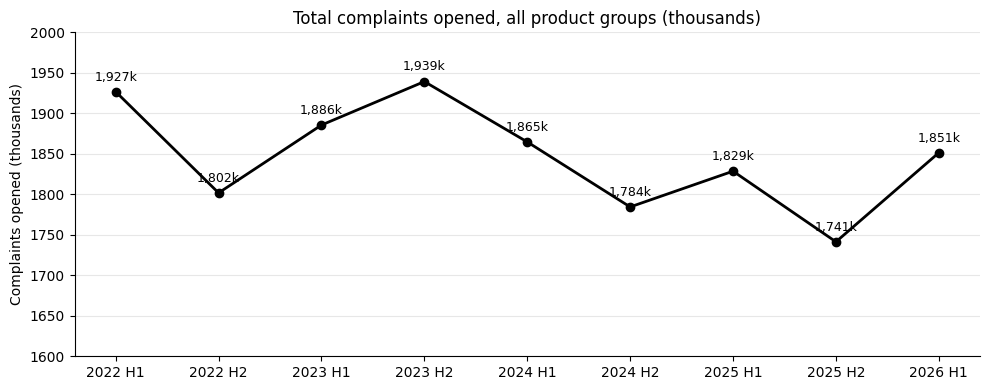

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
total_k = grp["All groups"] / 1000
ax.plot(grp.index, total_k, marker="o", color="black", linewidth=2)
for x, y in zip(grp.index, total_k):
    ax.annotate(f"{y:,.0f}k", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)
ax.set_title("Total complaints opened, all product groups (thousands)")
ax.set_ylabel("Complaints opened (thousands)")
ax.set_ylim(1600, 2000)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

*Note: the y-axis starts at 1,600k to make the changes visible; the swings are small relative to the total (about ±5%).*

### 2.2 Line chart: complaints by product group

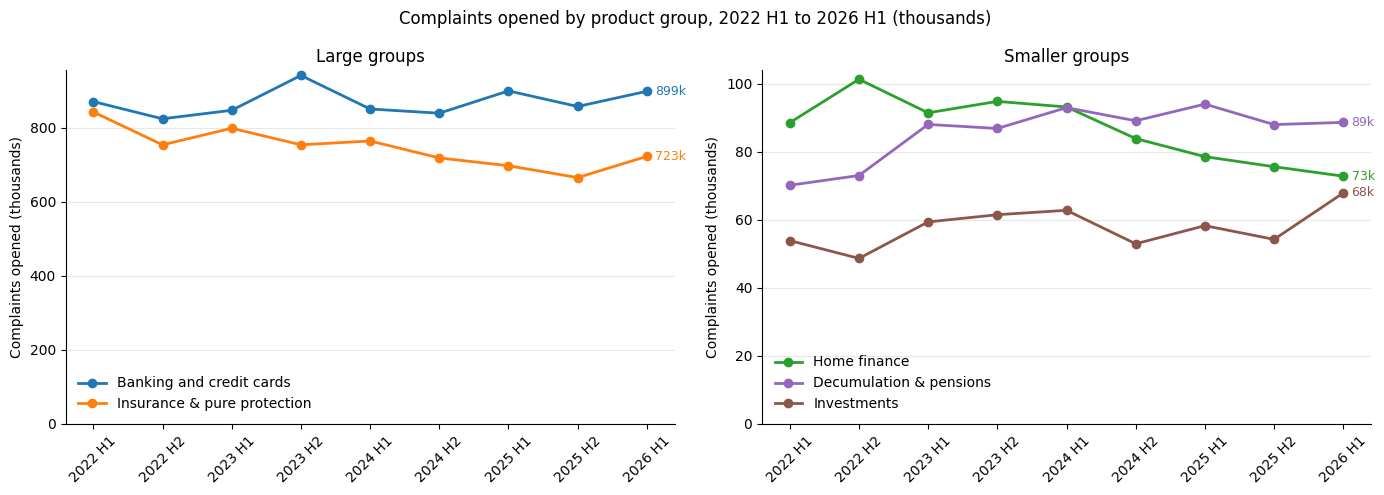

In [26]:
# Two panels: the two large groups and the three small groups have very different scales
big, small = GROUPS[:2], GROUPS[2:]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, groups, title in [(axes[0], big, "Large groups"), (axes[1], small, "Smaller groups")]:
    for g in groups:
        ax.plot(grp.index, grp[g] / 1000, marker="o", label=g, color=GROUP_COLOURS[g], linewidth=2)
        ax.annotate(f"{grp[g].iloc[-1] / 1000:,.0f}k", (len(grp) - 1, grp[g].iloc[-1] / 1000),
                    textcoords="offset points", xytext=(6, 0), va="center", fontsize=9,
                    color=GROUP_COLOURS[g])
    ax.set_title(title)
    ax.set_ylabel("Complaints opened (thousands)")
    ax.set_ylim(0, None)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower left")
fig.suptitle("Complaints opened by product group, 2022 H1 to 2026 H1 (thousands)")
plt.tight_layout()
plt.show()

*The two panels use different y-axis scales: the smaller groups have about a tenth of the complaints of banking or insurance.*

## 3. Overall change: 2022 H1 vs 2026 H1

% Change = (Current − Previous) ÷ Previous × 100, with Previous = 2022 H1 and Current = 2026 H1.

In [27]:
overall = pd.DataFrame({
    "2022 H1": grp.loc["2022 H1"],
    "2026 H1": grp.loc["2026 H1"],
})
overall["Change"] = overall["2026 H1"] - overall["2022 H1"]
overall["% change"] = (overall["Change"] / overall["2022 H1"] * 100).round(1)
overall = overall.sort_values("% change", ascending=False)
overall.style.format({"2022 H1": "{:,.0f}", "2026 H1": "{:,.0f}",
                      "Change": "{:+,.0f}", "% change": "{:+.1f}%"})

,2022 H1,2026 H1,Change,% change
Product Group,,,,
Decumulation & pensions,"70,201","88,701","+18,500",+26.4%
Investments,"53,926","67,935","+14,009",+26.0%
Banking and credit cards,"870,995","898,877","+27,882",+3.2%
All groups,"1,926,711","1,851,357","-75,354",-3.9%
Insurance & pure protection,"842,974","722,974","-120,000",-14.2%
Home finance,"88,615","72,870","-15,745",-17.8%


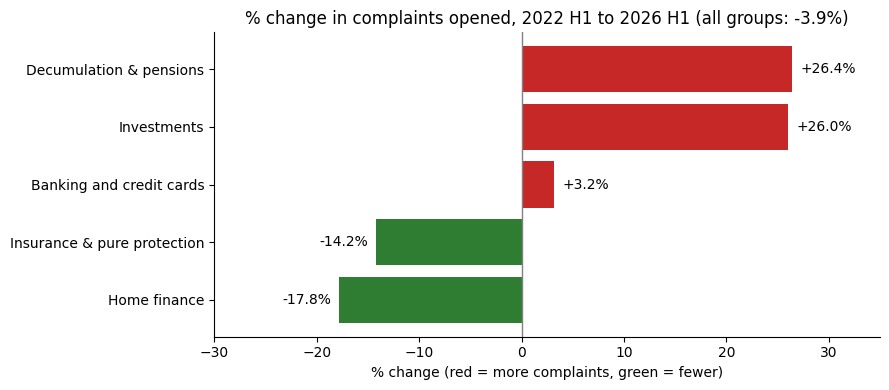

In [28]:
plot_df = overall.drop("All groups")
colours = ["#2e7d32" if v < 0 else "#c62828" for v in plot_df["% change"]]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(plot_df.index, plot_df["% change"], color=colours)
ax.axvline(0, color="grey", linewidth=1)
for b, v in zip(bars, plot_df["% change"]):
    ax.text(v + (0.8 if v >= 0 else -0.8), b.get_y() + b.get_height() / 2, f"{v:+.1f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=10)
ax.invert_yaxis()
ax.set_xlim(-30, 35)
ax.set_title(f"% change in complaints opened, 2022 H1 to 2026 H1 "
             f"(all groups: {overall.loc['All groups', '% change']:+.1f}%)")
ax.set_xlabel("% change (red = more complaints, green = fewer)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Which product groups contribute most to the total?

Each group's share of all complaints opened in that half-year.

In [29]:
share = grp[GROUPS].div(grp["All groups"], axis=0) * 100
share.round(1).style.format("{:.1f}%")

Product Group,Banking and credit cards,Insurance & pure protection,Home finance,Decumulation & pensions,Investments
Semester,,,,,
2022 H1,45.2%,43.8%,4.6%,3.6%,2.8%
2022 H2,45.8%,41.9%,5.6%,4.1%,2.7%
2023 H1,44.9%,42.4%,4.9%,4.7%,3.2%
2023 H2,48.6%,38.9%,4.9%,4.5%,3.2%
2024 H1,45.6%,41.0%,5.0%,5.0%,3.4%
2024 H2,47.1%,40.3%,4.7%,5.0%,3.0%
2025 H1,49.2%,38.2%,4.3%,5.1%,3.2%
2025 H2,49.3%,38.2%,4.3%,5.1%,3.1%
2026 H1,48.6%,39.1%,3.9%,4.8%,3.7%


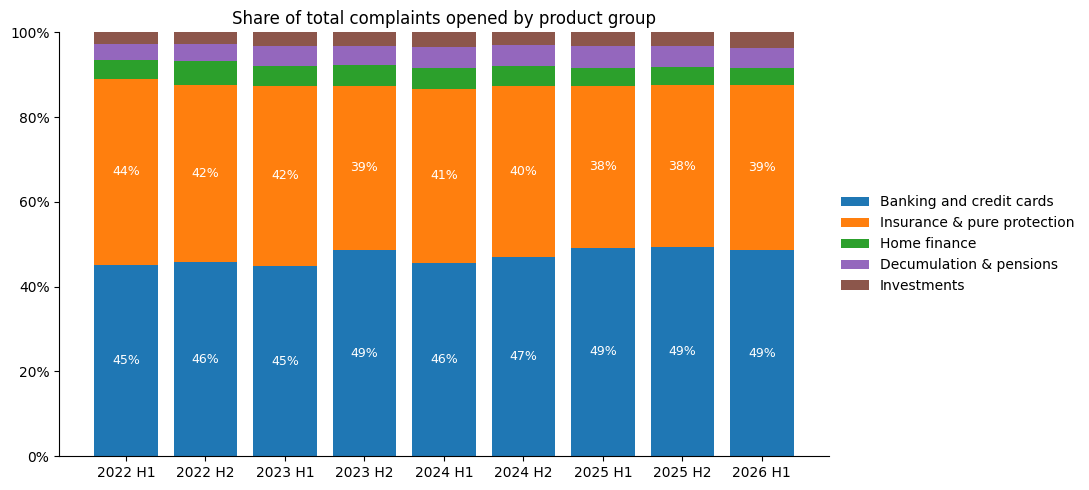

In [30]:
fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(share))
for g in GROUPS:
    ax.bar(share.index, share[g], bottom=bottom, label=g, color=GROUP_COLOURS[g])
    for i, (b, v) in enumerate(zip(bottom, share[g])):
        if v >= 10:   # label only slices big enough to fit text
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    bottom += share[g].values
ax.set_title("Share of total complaints opened by product group")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 5. Year-on-year change (same half-year, previous year)

Comparing H1 with the previous H1 (and H2 with the previous H2) avoids mixing in seasonal differences. Rows are in date order H1, H2, H1…, so "one year earlier" is **two rows back** (`periods=2`). The first year (2022) has nothing to compare against, so it is blank.

In [31]:
yoy = (grp.pct_change(periods=2, fill_method=None) * 100).round(1).dropna(how="all")
yoy.style.format("{:+.1f}%").background_gradient(cmap="RdYlGn_r", vmin=-20, vmax=20, axis=None)

Product Group,Banking and credit cards,Insurance & pure protection,Home finance,Decumulation & pensions,Investments,All groups
Semester,,,,,,
2023 H1,-2.7%,-5.2%,+3.3%,+25.5%,+10.2%,-2.1%
2023 H2,+14.2%,+0.0%,-6.4%,+18.9%,+26.4%,+7.6%
2024 H1,+0.4%,-4.3%,+1.9%,+5.6%,+5.7%,-1.1%
2024 H2,-10.8%,-4.7%,-11.5%,+2.6%,-13.9%,-8.0%
2025 H1,+5.7%,-8.8%,-15.7%,+1.1%,-7.2%,-1.9%
2025 H2,+2.2%,-7.4%,-9.9%,-1.3%,+2.5%,-2.4%
2026 H1,-0.1%,+3.6%,-7.3%,-5.7%,+16.5%,+1.2%


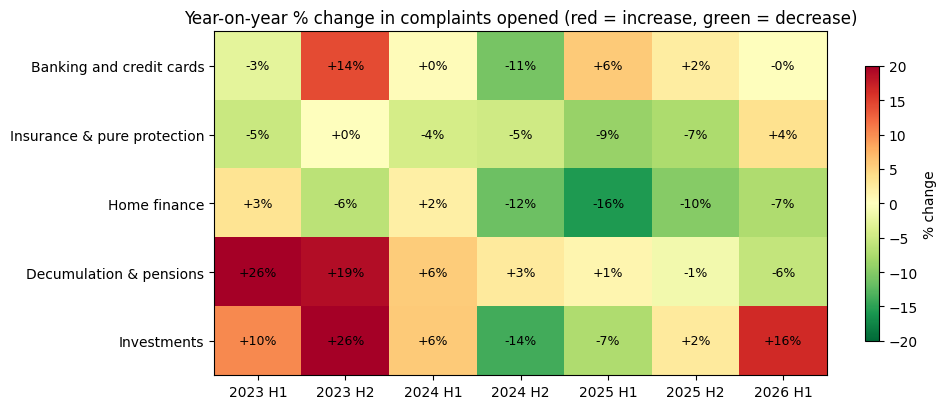

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.2))
data = yoy[GROUPS].T
im = ax.imshow(data.values, cmap="RdYlGn_r", vmin=-20, vmax=20, aspect="auto")
ax.set_xticks(range(len(data.columns)), data.columns)
ax.set_yticks(range(len(data.index)), data.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data.iat[i, j]:+.0f}%", ha="center", va="center", fontsize=9)
ax.set_title("Year-on-year % change in complaints opened (red = increase, green = decrease)")
fig.colorbar(im, ax=ax, label="% change", shrink=0.8)
plt.tight_layout()
plt.show()

## 6. Unusually large increases

We flag any half-year where a group's complaints rose by **10% or more** year-on-year. 10% is our own threshold, chosen because most YoY changes in the table above fall within ±10%.

In [33]:
THRESHOLD = 10
flags = (yoy[GROUPS].stack().rename("YoY % change").reset_index()
            .query("`YoY % change` >= @THRESHOLD")
            .sort_values("YoY % change", ascending=False))
flags

,Semester,Product Group,YoY % change
9,2023 H2,Investments,26.4
3,2023 H1,Decumulation & pensions,25.5
8,2023 H2,Decumulation & pensions,18.9
34,2026 H1,Investments,16.5
5,2023 H2,Banking and credit cards,14.2
4,2023 H1,Investments,10.2


### 6.1 Which products caused each jump?

For each flagged jump, we compare every product in that group with the same half-year a year earlier, and list the products with the biggest increases. This tells us whether a jump is broad or driven by one product.

In [34]:
prod = agg.pivot_table(index=["Product Group", "Product"], columns="Semester", values="Volume")
semesters = list(prod.columns)

def drivers(group, semester, top=3):
    prev = semesters[semesters.index(semester) - 2]   # same half-year, previous year
    d = prod.loc[group, [prev, semester]].copy()
    d["Change"] = d[semester] - d[prev]
    total_change = d["Change"].sum()
    d["Share of group change"] = (d["Change"] / total_change * 100).round(0)
    return d.sort_values("Change", ascending=False).head(top)

for _, row in flags.iterrows():
    print(f"\n{row['Product Group']}, {row['Semester']} (YoY {row['YoY % change']:+.1f}%)")
    display(drivers(row["Product Group"], row["Semester"]).style.format(
        {c: "{:,.0f}" for c in semesters} | {"Change": "{:+,.0f}", "Share of group change": "{:.0f}%"},
        na_rep=""))


Investments, 2023 H2 (YoY +26.4%)


Semester,2022 H2,2023 H2,Change,Share of group change
Product,,,,
ISAs (where investment held),"15,988","21,170","+5,182",40%
Investment bonds,"8,199","11,292","+3,093",24%
Platforms,"5,055","7,845","+2,790",22%



Decumulation & pensions, 2023 H1 (YoY +25.5%)


Semester,2022 H1,2023 H1,Change,Share of group change
Product,,,,
"Non-workplace personal pensions (e.g. SIPPs, SHPs, PPPs)","38,629","47,536","+8,907",50%
Annuities (including enhanced and impaired),"4,978","8,711","+3,733",21%
"Workplace personal pensions (e.g. SIPPs, SHPs, PPPs)","13,921","16,477","+2,556",14%



Decumulation & pensions, 2023 H2 (YoY +18.9%)


Semester,2022 H2,2023 H2,Change,Share of group change
Product,,,,
"Non-workplace personal pensions (e.g. SIPPs, SHPs, PPPs)","38,543","45,997","+7,454",54%
"Workplace personal pensions (e.g. SIPPs, SHPs, PPPs)","13,713","17,749","+4,036",29%
Annuities (including enhanced and impaired),"6,494","8,523","+2,029",15%


... (2 outputs left out)


Banking and credit cards, 2023 H2 (YoY +14.2%)


Semester,2022 H2,2023 H2,Change,Share of group change
Product,,,,
Other banking - Please provide details below,"28,197","73,419","+45,222",39%
Credit cards,"188,200","232,757","+44,557",38%
Savings (including ISAs),"69,373","91,177","+21,804",19%



Investments, 2023 H1 (YoY +10.2%)


Semester,2022 H1,2023 H1,Change,Share of group change
Product,,,,
Investment bonds,"7,603","11,053","+3,450",63%
ISAs (where investment held),"18,198","19,868","+1,670",30%
Platforms,"5,928","7,524","+1,596",29%


### 6.2 The biggest decreases, for context

The largest falls are explained by a small number of products too.

In [35]:
for g, s in [("Insurance & pure protection", "2023 H1"), ("Home finance", "2025 H1")]:
    prev = semesters[semesters.index(s) - 2]
    d = prod.loc[g, [prev, s]].copy()
    d["Change"] = d[s] - d[prev]
    print(f"\n{g}, {s} vs {prev}")
    display(d.sort_values("Change").head(3).style.format("{:,.0f}"))

# A large drop also happened half-on-half in 2022 H2 (Other general insurance)
d = prod.loc["Insurance & pure protection", ["2022 H1", "2022 H2"]].copy()
d["Change"] = d["2022 H2"] - d["2022 H1"]
print("\nInsurance & pure protection, 2022 H2 vs 2022 H1")
display(d.sort_values("Change").head(3).style.format("{:,.0f}"))


Insurance & pure protection, 2023 H1 vs 2022 H1


Semester,2022 H1,2023 H1,Change
Product,,,
Other general insurance,"252,795","150,771","-102,024"
General insurance packaged multi products,"23,796","19,727","-4,069"
Payment protection insurance,"6,687","3,287","-3,400"



Home finance, 2025 H1 vs 2024 H1


Semester,2024 H1,2025 H1,Change
Product,,,
Other regulated home finance products,"70,619","60,395","-10,224"
Other unregulated home finance products,"16,759","12,128","-4,631"
Equity release,"2,201","2,111",-90



Insurance & pure protection, 2022 H2 vs 2022 H1


Semester,2022 H1,2022 H2,Change
Product,,,
Other general insurance,"252,795","156,153","-96,642"
Property,"94,638","86,259","-8,379"
Motor & transport,"244,941","237,803","-7,138"


## 7. Is there a seasonal pattern (H1 vs H2)?

If complaints are seasonal, one half of the year should be consistently higher. We compare each H1 with the H2 that follows it.

In [36]:
h1 = grp.loc[[s for s in grp.index if s.endswith("H1") and s != "2026 H1"]]
h2 = grp.loc[[s for s in grp.index if s.endswith("H2")]]
seasonal = pd.DataFrame({
    "Average H1": h1.mean(),
    "Average H2": h2.mean(),
})
seasonal["H2 vs H1 %"] = ((seasonal["Average H2"] - seasonal["Average H1"]) / seasonal["Average H1"] * 100).round(1)
seasonal["Years where H1 > H2 (of 4)"] = (h1.values > h2.values).sum(axis=0)
seasonal.style.format({"Average H1": "{:,.0f}", "Average H2": "{:,.0f}", "H2 vs H1 %": "{:+.1f}%"})

,Average H1,Average H2,H2 vs H1 %,Years where H1 > H2 (of 4)
Product Group,,,,
Banking and credit cards,"867,358","865,880",-0.2%,3
Insurance & pure protection,"776,036","723,158",-6.8%,4
Home finance,"87,994","88,964",+1.1%,2
Decumulation & pensions,"86,355","84,300",-2.4%,3
Investments,"58,620","54,366",-7.3%,3
All groups,"1,876,364","1,816,668",-3.2%,3


In [37]:
# Summary table: what caused each unusually large increase
SHORT_GROUP = {"Banking and credit cards": "Banking", "Insurance & pure protection": "Insurance",
               "Home finance": "Home finance", "Decumulation & pensions": "Pensions",
               "Investments": "Investments"}
SHORT_PRODUCT = {"ISAs (where investment held)": "Investment ISAs",
                 "Non-workplace personal pensions  (e.g. SIPPs, SHPs, PPPs)": "Non-workplace pensions",
                 "Workplace personal pensions (e.g. SIPPs, SHPs, PPPs)": "Workplace pensions",
                 "Other banking - Please provide details below": "Other banking"}

rows = []
for _, r in flags.iterrows():
    g, s = r["Product Group"], r["Semester"]
    prev = semesters[semesters.index(s) - 2]          # same half-year, previous year
    change = (prod.loc[g, s] - prod.loc[g, prev]).sort_values(ascending=False)
    share = (change / change.sum() * 100).round(0)
    # show a second driver if it is almost as big as the first (within 5 points)
    top = [change.index[0]]
    if share.iloc[0] - share.iloc[1] <= 5:
        top.append(change.index[1])
    rows.append({
        "Group": SHORT_GROUP[g],
        "Period": s,
        "YoY change": f"{r['YoY % change']:+.1f}%",
        "Main driver": " / ".join(SHORT_PRODUCT.get(p.strip(), p.strip()) for p in top),
        "Share of increase": " / ".join(f"{share[p]:.0f}%" for p in top),
    })

jump_drivers = pd.DataFrame(rows)
jump_drivers.style.hide(axis="index")

Group,Period,YoY change,Main driver,Share of increase
Investments,2023 H2,+26.4%,Investment ISAs,40%
Pensions,2023 H1,+25.5%,Non-workplace pensions,50%
Pensions,2023 H2,+18.9%,Non-workplace pensions,54%
Investments,2026 H1,+16.5%,Platforms,51%
Banking,2023 H2,+14.2%,Other banking / Credit cards,39% / 38%
Investments,2023 H1,+10.2%,Investment bonds,63%


*Uses the four complete years (2022–2025). 2026 H2 is not yet published.*

## 8. Summary of findings

**1. Overall, complaints are broadly flat to slightly down.** Total complaints opened fell from about 1.93 million in 2022 H1 to 1.85 million in 2026 H1 (−3.9%). The total moved within a narrow band of roughly 1.74–1.94 million per half-year, with no sustained rise.

**2. Two product groups make up almost 90% of all complaints.** Banking & credit cards (about 45–49%) and Insurance & pure protection (about 38–44%) dominate in every period. Banking's share has grown from 45% to 49%, mainly because insurance complaints fell rather than banking complaints rising (banking +3.2% over the period).

**3. The groups are moving in different directions.**
- Rising: Decumulation & pensions (+26.4%) and Investments (+26.0%), though both start from small bases (under 5% of the total each).
- Falling: Home finance (−17.8%, down in each of the last five half-years) and Insurance & pure protection (−14.2%).

**4. Unusually large increases are usually driven by one or two products.**
- Banking & credit cards, 2023 H2 (+14.2% YoY): mostly "Other banking" (28k to 73k, a one-off that dropped back to 22k the next half-year) plus credit cards (+31k).
- Investments, 2026 H1 (+16.5% YoY): about half the increase came from Platforms (8.0k to 12.9k).
- Investments, 2023 H2 (+26.4% YoY): mainly ISAs (where investment held) and investment bonds.
- Decumulation & pensions, 2023 H1 and 2023 H2 (+25.5%, +18.9%): about half of each increase came from non-workplace personal pensions.

**5. Complaints tend to be higher in H1 than in H2.** In three of the four complete years, total complaints were higher in H1 than in the following H2 (on average about 3% higher). 2023 was the exception, caused by the one-off "Other banking" spike. Insurance shows the clearest pattern: H1 was higher in all four years, by about 7% on average. This is why year-on-year comparison is more reliable than comparing consecutive half-years.

**6. One product explains the insurance decline.** "Other general insurance" dropped from 253k in 2022 H1 to 156k in 2022 H2 and has stayed around 110–120k since. Its fall (about −136k) is larger than the whole insurance group's fall over the period (about −120k), so the other insurance products, taken together, grew slightly.

## 9. Caveats
- These are complaint **volumes**, not rates. A group can have more complaints simply because it has more customers. Volumes are compared with rates in Part 2 (Q3).
- Complaints are a signal of customer dissatisfaction, not a direct measure of product quality.
- The FCA notes firms sometimes resubmit data, and the 2025 figures were revised after a firm reporting anomaly; we use the 2026 H1 release, which includes those revisions.
- Firms report on their own half-year periods, so "H1" for some firms does not exactly match January–June.

# Part D — EDA 2: Product-level rankings and complaint shares

Source: `EDA_Part_2_(Palmy).ipynb`. This analysis now uses `product_df` rather than an ambiguous global `df`. It reads the **same shared cleaned aggregate file** as Part C.

In [38]:
# Reuse the shared Drive path; never a machine-specific local path.
product_df = pd.read_csv(AGGREGATE_CLEAN_CSV)
product_df['Product'] = product_df['Product'].astype('string').str.strip()
print('Shared product-level EDA dataset:', AGGREGATE_CLEAN_CSV)
display(product_df.head())
product_df.info()
print('Missing values by column:')
display(product_df.isna().sum())

Shared product-level EDA dataset: /content/drive/MyDrive/Project lab dataset/aggregate_filtered_2022H1_2026H1.csv


,Semester,Product Group,Product,Variable type,Volume
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Semester       450 non-null    object
 1   Product Group  450 non-null    object
 2   Product        450 non-null    string
 3   Variable type  450 non-null    object
 4   Volume         450 non-null    int64 
dtypes: int64(1), object(3), string(1)
memory usage: 17.7+ KB
Missing values by column:


,0
Semester,0
Product Group,0
Product,0
Variable type,0
Volume,0


In [39]:

# Calculate total complaints for each financial product
product_ranking = product_df.groupby("Product")["Volume"].sum()

# Sort from most to least complained-about
product_ranking = product_ranking.sort_values(ascending=False)

# Convert into a dataframe
product_ranking = product_ranking.reset_index()

# Add ranking numbers
product_ranking.index = product_ranking.index + 1
product_ranking.index.name = "Rank"

# Display ALL products
display(product_ranking)

,Product,Volume
Rank,,
1,Current accounts,4597403
2,Motor & transport,2259804
3,Credit cards,1911420
4,Other general insurance,1263848
5,Property,826449
6,Savings (including ISAs),720857
7,Medical/health,715651
8,Other regulated home finance products,595836
9,Warranty,490596


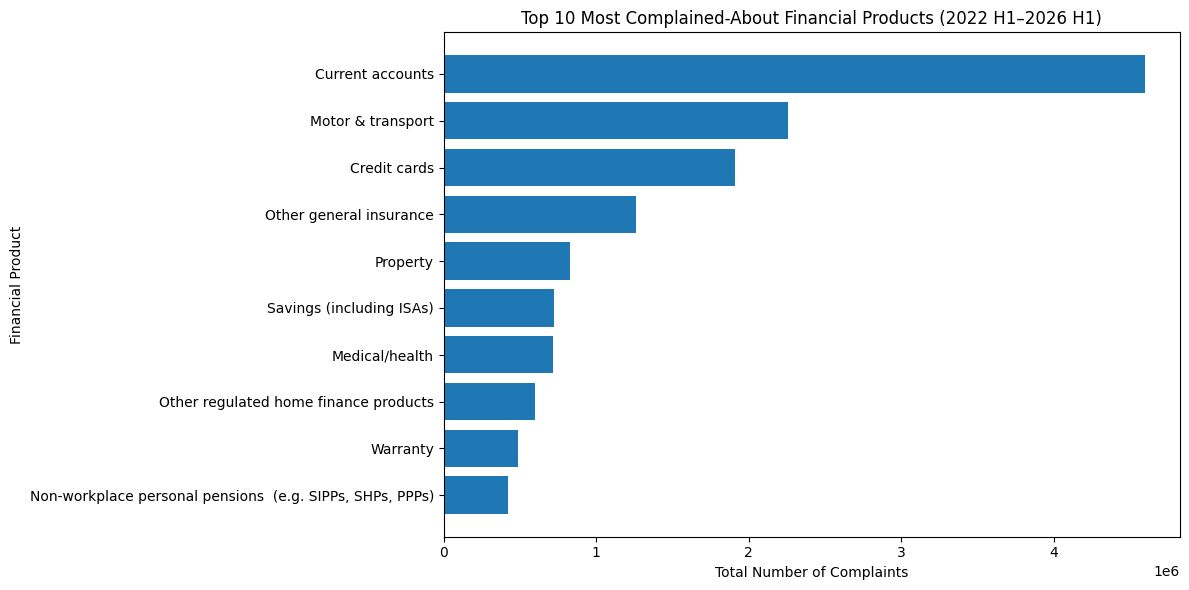

In [40]:

# Select the top 10 products from the ranking
product_top10 = product_ranking.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(product_top10["Product"], product_top10["Volume"])

plt.xlabel("Total Number of Complaints")
plt.ylabel("Financial Product")
plt.title("Top 10 Most Complained-About Financial Products (2022 H1–2026 H1)")

# Highest-ranked product at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

The above graph demonstrates which products consistently receive the most complaints across all nine semesters (2022 H1–2026 H1).

In [41]:
#Below we then move onto seeing the ranking for each semester

product_df["Rank"] = product_df.groupby("Semester")["Volume"].rank(
    ascending=False,
    method="min"
)

# View the rankings
display(
    product_df[["Semester", "Product", "Volume", "Rank"]]
    .sort_values(["Semester", "Rank"])
)

,Semester,Product,Volume,Rank
1,2022 H1,Current accounts,528850,1.0
26,2022 H1,Other general insurance,252795,2.0
25,2022 H1,Motor & transport,244941,3.0
0,2022 H1,Credit cards,199359,4.0
30,2022 H1,Property,94638,5.0
...,...,...,...,...
411,2026 H1,Other pensions,242,46.0
441,2026 H1,Investment packaged multi products,143,47.0
413,2026 H1,"Third way products (e.g. investment linked, va...",51,48.0
410,2026 H1,Other decumulation,15,49.0


In [42]:
#we then count how often each product appears in the top 10 to measure consistency
top10_each_semester = product_df[product_df["Rank"] <= 10]

# Count how many semesters each product appears in the top 10
consistency = (
    top10_each_semester.groupby("Product")["Semester"]
    .nunique()
    .sort_values(ascending=False)
)

# Display the results
display(consistency.reset_index(name="Semesters in Top 10"))


,Product,Semesters in Top 10
0,Credit cards,9
1,Current accounts,9
2,Medical/health,9
3,Motor & transport,9
4,Other regulated home finance products,9
5,Other general insurance,9
6,Savings (including ISAs),9
7,Property,9
8,Warranty,8
9,"Non-workplace personal pensions (e.g. SIPPs, ...",8


This table shows how consistently financial products ranked among the 10 most complained-about products across nine semesters (2022 H1–2026 H1). Eight products appeared in the top 10 in every semester, suggesting that the distribution of high complaint volumes across financial products remained relatively stable throughout the period.

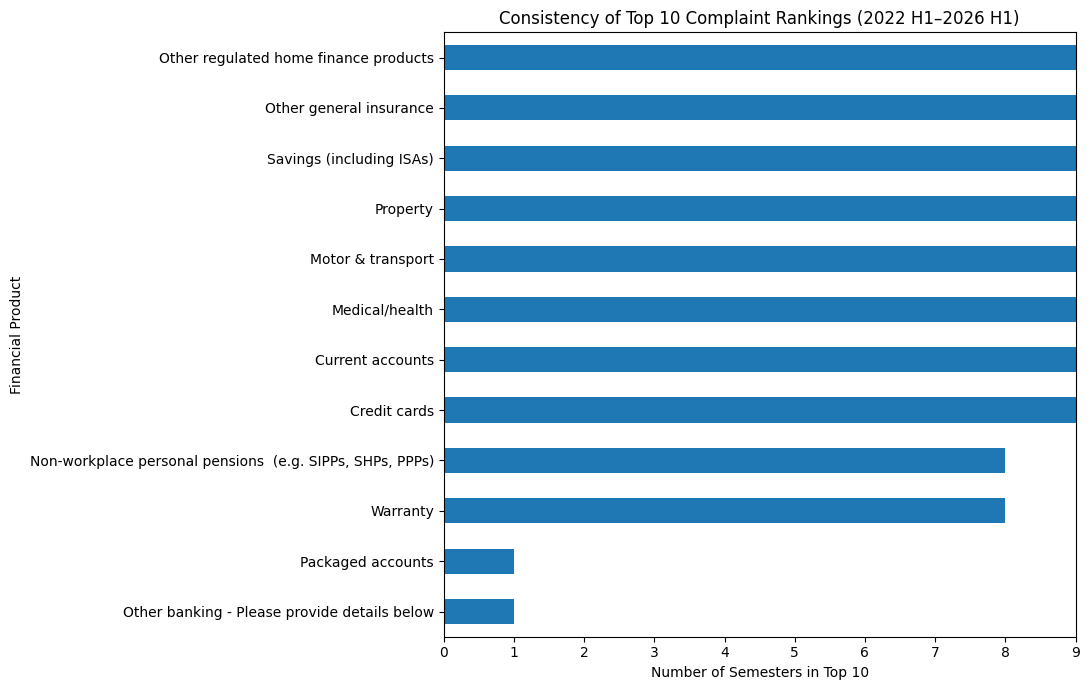

In [43]:
#To visualise how consistently products appear in the top 10

# Plot frequency of top 10 appearances
plt.figure(figsize=(11, 7))

consistency.sort_values().plot(kind="barh")

plt.xlabel("Number of Semesters in Top 10")
plt.ylabel("Financial Product")
plt.title("Consistency of Top 10 Complaint Rankings (2022 H1–2026 H1)")

plt.xlim(0, 9)
plt.xticks(range(0, 10))

plt.tight_layout()
plt.show()

**Note.** Consistently high complaint volumes don't necessarily indicate that a financial product is more problematic. Some products, such as current accounts, are used by far more consumers. The findings describe reported complaint volumes, not the likelihood of an individual customer making a complaint.

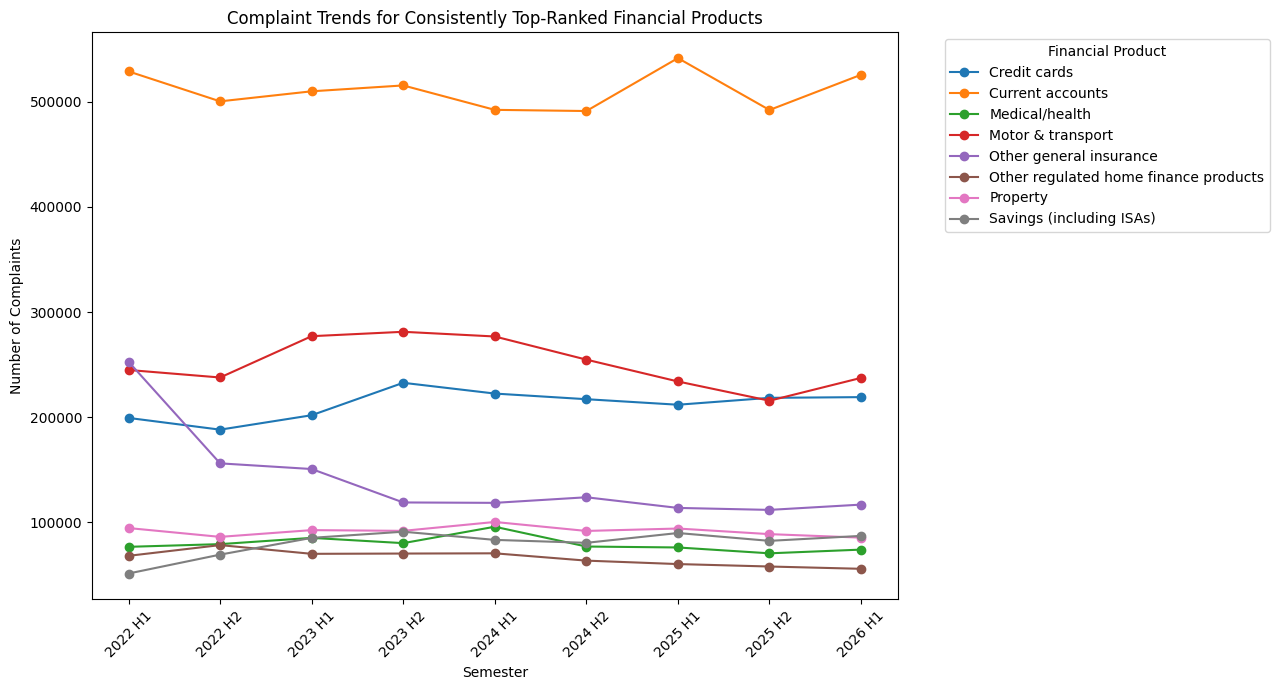

In [44]:
# Select products appearing in the top 10 in all 9 semesters
consistent_products = consistency[consistency == 9].index

# Filter the dataset
df_consistent = product_df[product_df["Product"].isin(consistent_products)]

# Prepare the data for plotting
product_trend = df_consistent.pivot(
    index="Semester",
    columns="Product",
    values="Volume"
)

# Arrange semesters chronologically
product_periods = [
    "2022 H1", "2022 H2",
    "2023 H1", "2023 H2",
    "2024 H1", "2024 H2",
    "2025 H1", "2025 H2",
    "2026 H1"
]

product_trend = product_trend.reindex(product_periods)

# Create line chart
product_trend.plot(figsize=(13, 7), marker="o")

plt.title("Complaint Trends for Consistently Top-Ranked Financial Products")
plt.xlabel("Semester")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.legend(title="Financial Product", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


**Note.** The line chart illustrates complaint trends among the eight financial products consistently ranked in the top 10 between 2022 H1 and 2026 H1. Current accounts maintained the highest complaint volumes throughout, with relatively limited fluctuations. Motor and transport complaints exhibited greater variation, while other general insurance experienced a substantial decline, particularly between 2022 H1 and 2022 H2. Overall, despite fluctuations in complaint volumes, the most complained-about financial products remained largely consistent across the nine semesters.

In [45]:
product_totals = product_df.groupby("Product")["Volume"].sum()

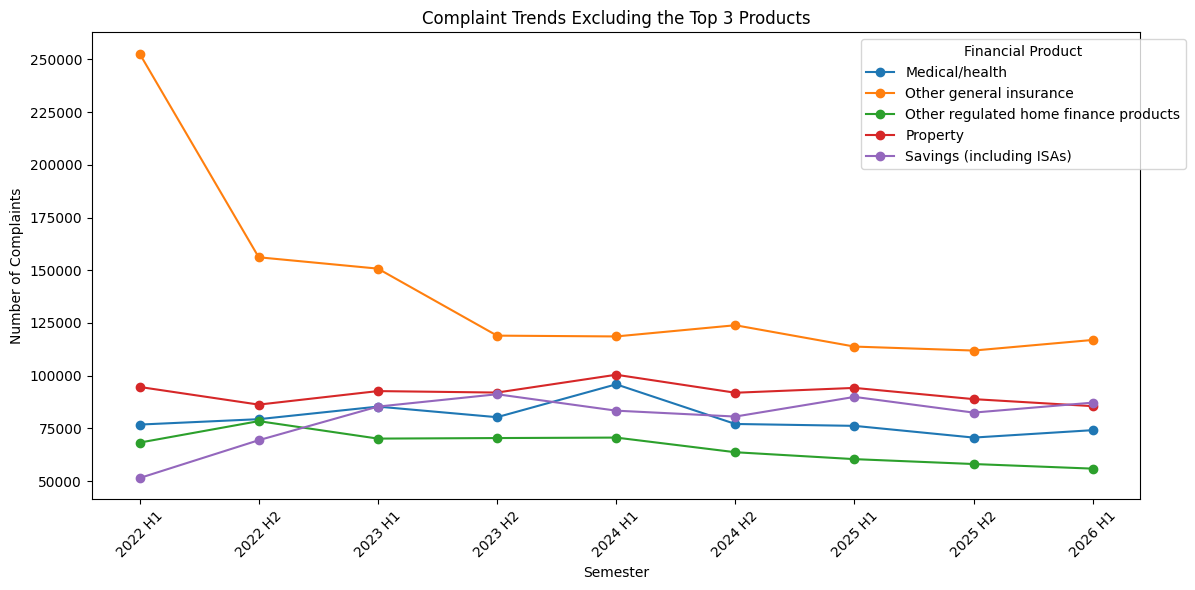

In [46]:

# Calculate total complaints for each product
product_totals = product_df.groupby("Product")["Volume"].sum()

# Identify the three products with the most complaints
top3 = product_totals.nlargest(3).index

# Exclude those three products from the trend chart
remaining = product_trend.drop(columns=top3)

# Plot the remaining products
remaining.plot(figsize=(12, 6), marker="o")

plt.title("Complaint Trends Excluding the Top 3 Products")
plt.xlabel("Semester")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.legend(title="Financial Product", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

**Note.** Excluding the three highest-volume products reveals additional variation in complaint trends. Other general insurance experienced a substantial decline, particularly between 2022 H1 and 2022 H2, while savings products (including ISAs) showed an overall increase. Property insurance complaints remained relatively stable, whereas medical/health and other regulated home finance products experienced fluctuations or gradual declines. These findings highlight differences in complaint trends despite all five products consistently ranking among the ten most complained-about throughout the period.

In [47]:
# We then calculate the percentage change in complaints for all 50 financial products between 2022 H1 to 2026 H1. This helps identify which products experienced the largest increases and decreases, even if they weren't in the top 10.


# Select complaints from the first and last semesters
product_comparison = product_df[product_df["Semester"].isin(["2022 H1", "2026 H1"])]

# Create separate columns for each semester
product_comparison = product_comparison.pivot(
    index="Product",
    columns="Semester",
    values="Volume"
)

# Calculate absolute change
product_comparison["Absolute Change"] = (
    product_comparison["2026 H1"] - product_comparison["2022 H1"]
)

# Calculate percentage change
product_comparison["Percentage Change"] = (
    product_comparison["Absolute Change"] /
    product_comparison["2022 H1"].replace(0, float("nan")) * 100
)

# Rank all products by percentage change
product_comparison = product_comparison.sort_values(
    "Percentage Change",
    ascending=False
)

display(product_comparison.round(2))

Semester,2022 H1,2026 H1,Absolute Change,Percentage Change
Product,,,,
Decumulation packaged multi products,25,590,565,2260.00
Investment packaged multi products,48,143,95,197.92
Protection packaged multi products,487,1064,577,118.48
Platforms,5928,12874,6946,117.17
ETPs,326,682,356,109.20
Travel,22386,42215,19829,88.58
Overdrafts,14648,26629,11981,81.79
Warranty,44077,78119,34042,77.23
Savings (including ISAs),51419,87204,35785,69.59


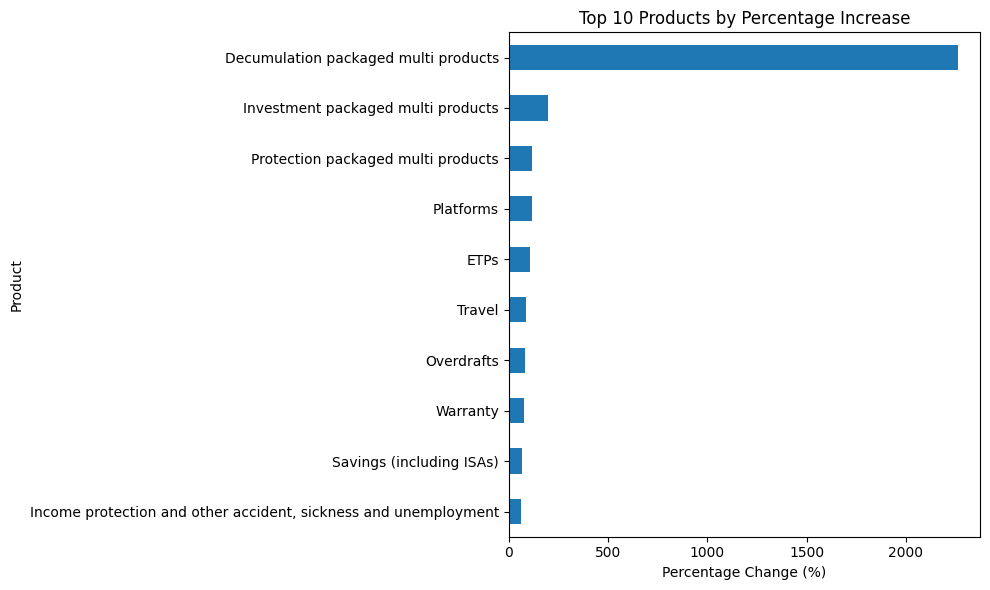

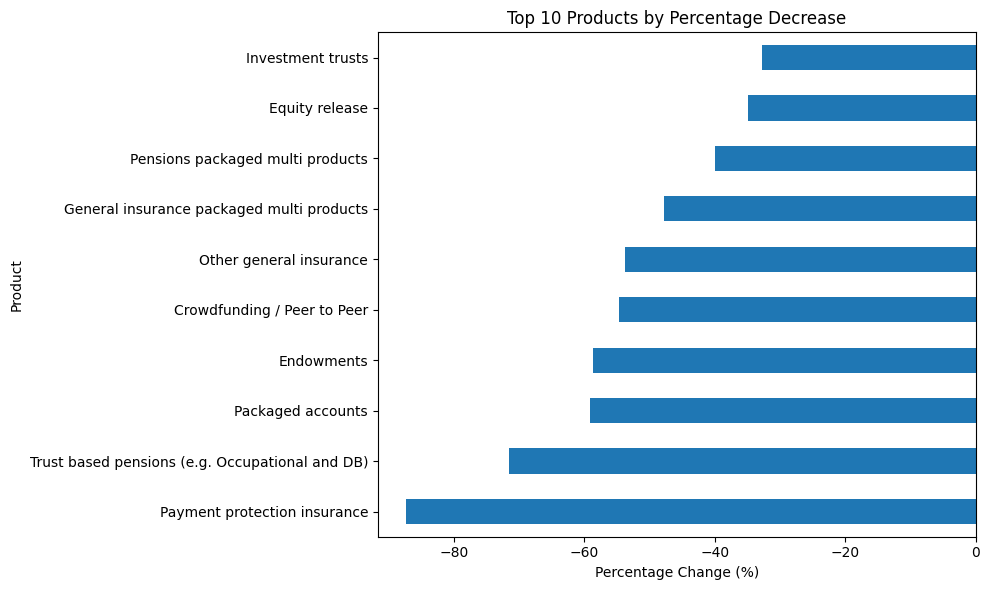

In [48]:
#to visualise the biggest increases and decreases

# Select the 10 largest increases
biggest_increases = product_comparison.nlargest(10, "Percentage Change")

# Select the 10 largest decreases
biggest_decreases = product_comparison.nsmallest(10, "Percentage Change")

# Create two separate charts
biggest_increases["Percentage Change"].sort_values().plot(
    kind="barh", figsize=(10, 6),
    title="Top 10 Products by Percentage Increase"
)
plt.xlabel("Percentage Change (%)")
plt.tight_layout()
plt.show()

biggest_decreases["Percentage Change"].sort_values().plot(
    kind="barh", figsize=(10, 6),
    title="Top 10 Products by Percentage Decrease"
)
plt.xlabel("Percentage Change (%)")
plt.tight_layout()
plt.show()


While the decumulation packaged multi products experienced a massive 2,260% increase, but this represents only 565 additional complaints.

Meanwhile, savings products experienced a smaller percentage increase of 69.59%, but this represents 35,785 additional complaints.

So percentage change alone can be misleading when starting volumes are very small.

However, decumulation packaged multi products appears as an outlier in the percentage-change analysis, increasing by 2260% between 2022 H1 and 2026 H1. However, this reflects a rise from only 25 to 590 complaints, so the extreme percentage change is largely due to the very low starting value rather than a large absolute increase.

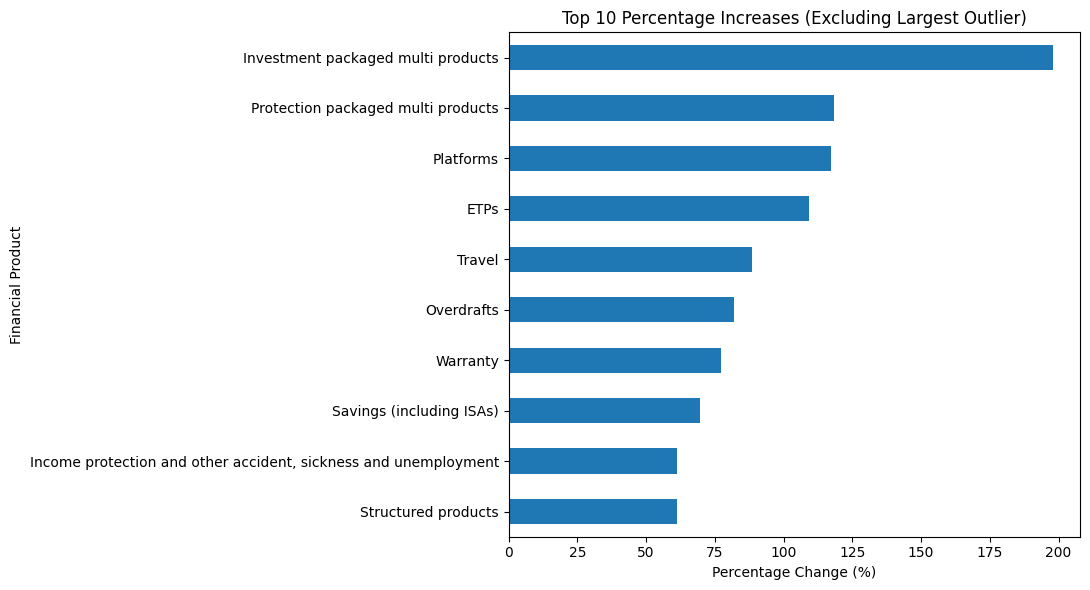

In [49]:
#we decided to improve the percentage-increase chart


# Exclude the largest percentage-change outlier from the chart
increases_no_outlier = product_comparison.nlargest(
    11, "Percentage Change"
).iloc[1:]

# Plot the remaining 10 products
increases_no_outlier["Percentage Change"].sort_values().plot(
    kind="barh",
    figsize=(11, 6)
)

plt.title("Top 10 Percentage Increases (Excluding Largest Outlier)")
plt.xlabel("Percentage Change (%)")
plt.ylabel("Financial Product")
plt.tight_layout()
plt.show()

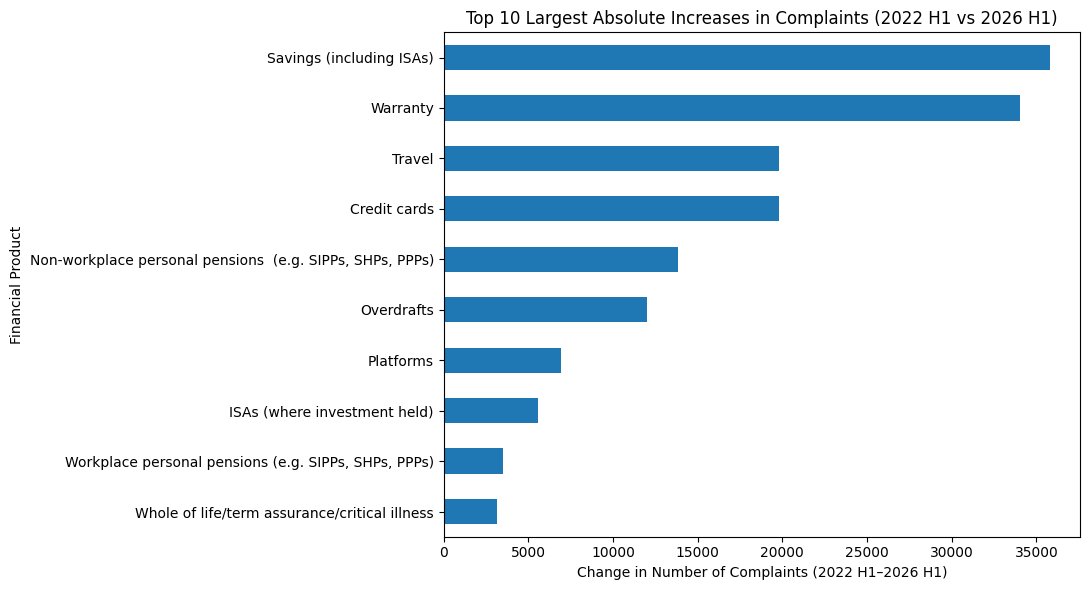

In [50]:
#Utilising absolute changes to validate percentage changes

# Identify products with the largest absolute increases
absolute_increases = product_comparison.nlargest(
    10, "Absolute Change"
)

# Plot
absolute_increases["Absolute Change"].sort_values().plot(
    kind="barh",
    figsize=(11, 6)
)

plt.title("Top 10 Largest Absolute Increases in Complaints (2022 H1 vs 2026 H1)")
plt.xlabel("Change in Number of Complaints (2022 H1–2026 H1)")
plt.ylabel("Financial Product")
plt.tight_layout()
plt.show()


**Note.** Between 2022 H1 and 2026 H1, savings products (including ISAs) recorded the largest absolute increase in complaints (+35,785), followed by warranty products (+34,042). Travel insurance and credit cards also experienced substantial increases of approximately 19,800 complaints each. Notably, products with the greatest absolute increases did not necessarily experience the largest percentage increases, highlighting how initial complaint volumes influence relative growth.

Both absolute and percentage changes were examined to provide a more comprehensive understanding of complaint trends. While percentage changes highlight relative growth or decline, absolute changes reveal the actual increase or decrease in complaint volumes. For example, decumulation packaged multi products experienced the largest percentage increase (2,260%), but savings products recorded a substantially larger absolute increase (+35,785 complaints).

# **Complaint Share**

Complaint share tells us what proportion of all complaints in a given semester came from each financial product. It helps us understand whether complaints became more concentrated around certain products.

In [51]:
# Calculate total complaints in each semester
semester_totals = product_df.groupby("Semester")["Volume"].sum()

# Map total semester complaints back to each row
product_df["Semester Total"] = product_df["Semester"].map(semester_totals)

# Calculate complaint share as a percentage
product_df["Complaint Share (%)"] = (product_df["Volume"] / product_df["Semester Total"]) * 100

# Check the result
display(product_df.head())

,Semester,Product Group,Product,Variable type,Volume,Rank,Semester Total,Complaint Share (%)
0,2022 H1,Banking and credit cards,Credit cards,Complaints opened,199359,4.0,1926711,10.347115
1,2022 H1,Banking and credit cards,Current accounts,Complaints opened,528850,1.0,1926711,27.448330
2,2022 H1,Banking and credit cards,Other banking - Please provide details below,Complaints opened,30784,12.0,1926711,1.597749
3,2022 H1,Banking and credit cards,Overdrafts,Complaints opened,14648,20.0,1926711,0.760259
4,2022 H1,Banking and credit cards,Packaged accounts,Complaints opened,45935,9.0,1926711,2.384115


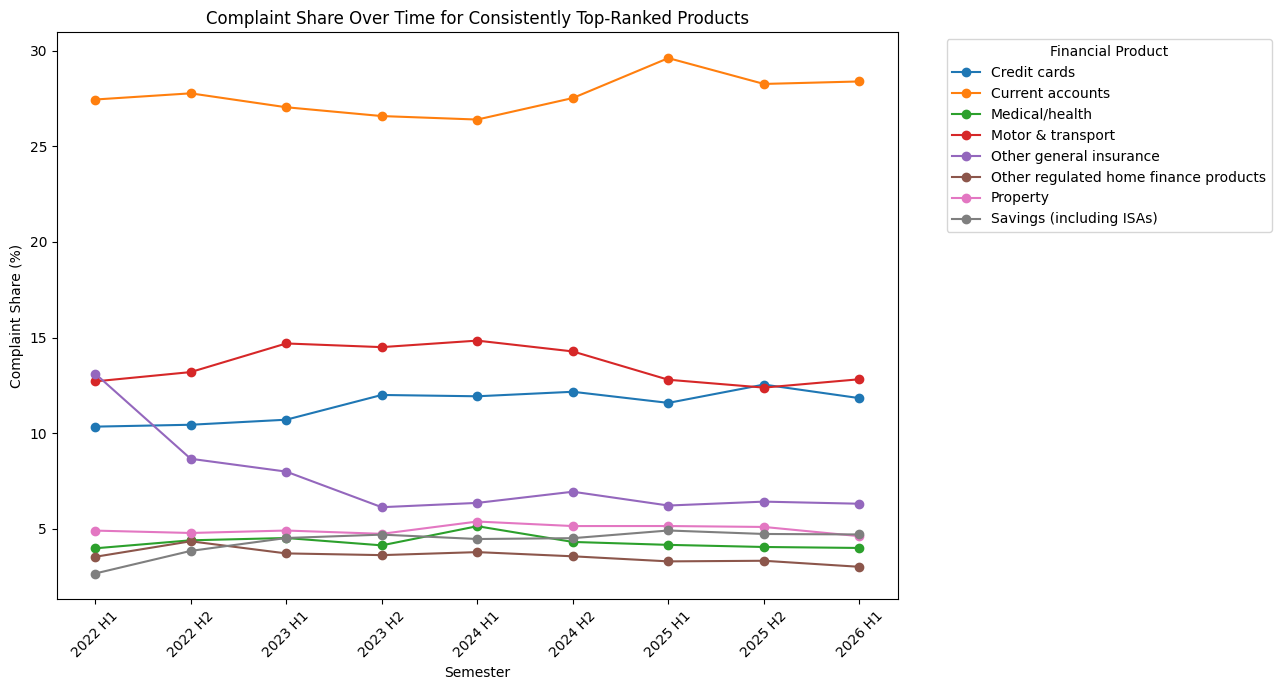

In [52]:
# Use the products that appeared in the top 10 in all 9 semesters
consistent_products = consistency[consistency == 9].index

# Filter data
df_share = product_df[product_df["Product"].isin(consistent_products)]

# Pivot for plotting
share_trend = df_share.pivot(
    index="Semester",
    columns="Product",
    values="Complaint Share (%)"
)

# Put semesters in the correct order
product_periods = [
    "2022 H1", "2022 H2",
    "2023 H1", "2023 H2",
    "2024 H1", "2024 H2",
    "2025 H1", "2025 H2",
    "2026 H1"
]

share_trend = share_trend.reindex(product_periods)

# Plot
share_trend.plot(figsize=(13, 7), marker="o")

plt.title("Complaint Share Over Time for Consistently Top-Ranked Products")
plt.xlabel("Semester")
plt.ylabel("Complaint Share (%)")
plt.xticks(rotation=45)
plt.legend(title="Financial Product", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

**Note.** Current accounts became slightly more dominant in the overall complaint distribution despite a small decline in their absolute complaint volume.

In [53]:
display(
    product_df[product_df["Product"] == "Current accounts"][
        ["Semester", "Product", "Volume", "Complaint Share (%)"]
    ]
)

,Semester,Product,Volume,Complaint Share (%)
1,2022 H1,Current accounts,528850,27.448330
51,2022 H2,Current accounts,500371,27.771620
101,2023 H1,Current accounts,509924,27.044053
151,2023 H2,Current accounts,515502,26.583175
201,2024 H1,Current accounts,492289,26.400921
251,2024 H2,Current accounts,491172,27.525937
301,2025 H1,Current accounts,541493,29.613310
351,2025 H2,Current accounts,492149,28.262708
401,2026 H1,Current accounts,525653,28.392849


Complaint share analysis reveals changes in the distribution of consumer complaints across financial products between 2022 H1 and 2026 H1. Current accounts consistently accounted for the largest proportion of complaints (approximately 26–30%), while other general insurance experienced a substantial decline in its share from 13.1% to 6.3%. In contrast, savings products (including ISAs) increased their share from approximately 2.7% to 4.7%. Overall, although the most complained-about products remained relatively consistent, their contributions to total complaints shifted over time.

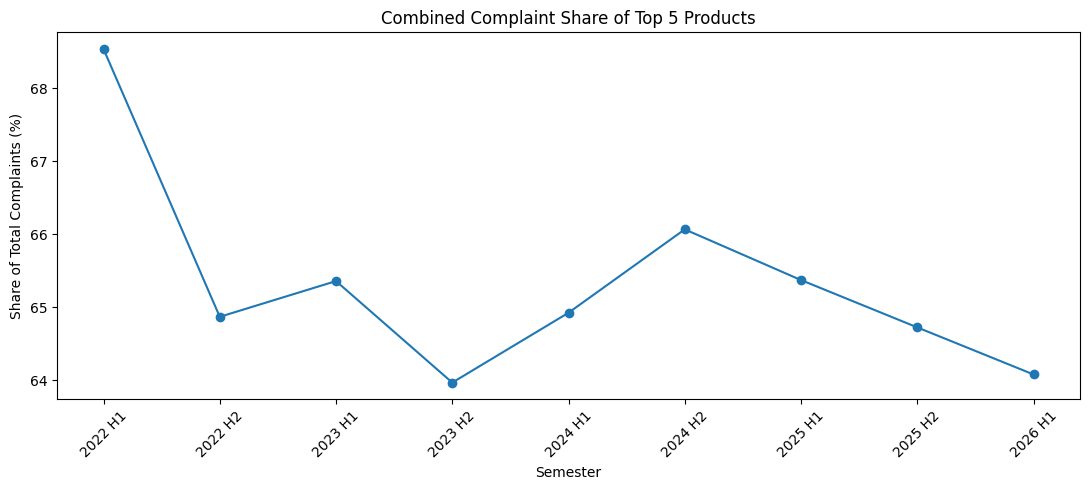

,Complaint Share (%)
Semester,
2022 H1,68.54
2022 H2,64.87
2023 H1,65.36
2023 H2,63.97
2024 H1,64.93
2024 H2,66.07
2025 H1,65.37
2025 H2,64.73
2026 H1,64.08


In [54]:

# Rank products by complaints within each semester
product_df["Rank"] = product_df.groupby("Semester")["Volume"].rank(
    ascending=False,
    method="first"
)

# Select the top 5 products in each semester
top5_each_semester = product_df[product_df["Rank"] <= 5]

# Calculate their combined complaint share
top5_share = (
    top5_each_semester.groupby("Semester")["Complaint Share (%)"]
    .sum()
    .reindex(product_periods)
)

# Plot
top5_share.plot(figsize=(11, 5), marker="o")

plt.title("Combined Complaint Share of Top 5 Products")
plt.xlabel("Semester")
plt.ylabel("Share of Total Complaints (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display exact values
display(top5_share.round(2))

The five financial products receiving the most complaints overall were current accounts, motor & transport, credit cards, other general insurance, and property insurance.

The combined complaint share of the five highest-ranked products in each semester decreased from 68.54% in 2022 H1 to 64.08% in 2026 H1, a decline of 4.46 percentage points. Although complaint concentration fluctuated throughout the period, the overall decrease suggests that complaints became slightly more dispersed across financial products. Nevertheless, the top five products continued to account for approximately two-thirds of total complaints, indicating that complaint volumes remained relatively concentrated.

**Summary of Key Findings**

Exploratory Data Analysis of FCA complaints data from 2022 H1 to 2026 H1 revealed that consumer complaints were consistently concentrated among a relatively small number of financial products.

Current accounts received the highest cumulative complaint volume (4.60 million), followed by motor & transport (2.26 million) and credit cards (1.91 million). Eight financial products consistently appeared in the top 10 across all nine semesters, indicating relatively stable product rankings.

However, complaint trends varied considerably. Savings products recorded the largest absolute increase (+35,785 complaints), while other general insurance experienced the largest absolute decrease (−135,858). Decumulation packaged multi products showed the greatest percentage increase (+2,260%), although this reflected a relatively small absolute increase (+565), highlighting the potential distortion caused by low initial complaint volumes.

Complaint share analysis revealed that current accounts remained the dominant category, while savings gained prominence and other general insurance declined. Furthermore, the combined share of the five most complained-about products in each semester fell from 68.54% to 64.08%, suggesting a modest reduction in complaint concentration.

Overall, although the most complained-about financial products remained largely consistent, their complaint volumes and relative contributions changed over time.

# Part E — EDA 3: Firm-level analysis (9 steps)

Source: `EDA_Firm_Level.ipynb`. Uses the **same shared Drive folder** (subfolder `Firm level data`) instead of the original `gdown` file URL. `firm_source` is intentionally separate from `product_df` and `agg`. The original nine analysis steps, interpretations and export tables are retained.

# FCA Firm-level EDA — 9-step analysis
**2022 H1–2026 H1 · Opened complaints · All five product groups**

**Main objective:** Which reporting firms have the most opened complaints, which product groups account for these counts *within firms*, and which comparable firms contribute to changes over time?

**Scope:** Firm-level published records only. This is **not** an industry census, a complaint-rate analysis, a diagnosis of complaint causes, or the separate product-level EDA.

**How to use:** Run the notebook from top to bottom. All data are loaded using the shared Google Drive folder set in Part 0. The EDA does not apply additional automatic cleaning.

**Important:** Counts are complaints opened, not complaints per 1,000 accounts. Firm sizes differ. Missing product groups are **not zero**. Reporting dates and joint reporting may differ.

## Setup — Read the firm dataset from the shared Drive folder

**What we do:** Load `firm_level_opened_2022H1_2026H1.csv` from the shared `Firm level data` subfolder, check its columns, then conduct the EDA. No `gdown`, public link, or local CSV copy is required.

In [55]:
# Same shared Google Drive path used in Parts A–D, but for firm-level data.
firm_source = pd.read_csv(FIRM_CLEAN_CSV)
print('Shared firm EDA dataset:', FIRM_CLEAN_CSV)
print('Dataset shape:', firm_source.shape)
display(firm_source.head())

Shared firm EDA dataset: /content/drive/MyDrive/Project lab dataset/Firm level data/firm_level_opened_2022H1_2026H1.csv
Dataset shape: (2003, 10)


,Semester,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
0,2022 H1,Accord Mortgages Limited,ACCORD MORTGAGES LIMITED,no,2022-01-01 to 2022-06-30,3.0,NaN,605.0,NaN,NaN
1,2022 H1,Acm Ulr Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,1261.0,NaN
2,2022 H1,Adrian Flux Insurance Services Group,NO GROUP,no,2021-09-01 to 2022-02-28,NaN,NaN,NaN,1058.0,NaN
3,2022 H1,Advanced Payment Solutions Limited,NO GROUP,no,2021-10-01 to 2022-03-31,989.0,NaN,NaN,NaN,NaN
4,2022 H1,Advisory Insurance Brokers Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,591.0,NaN


## Data selection — Use all five product groups
**What we do:** Select columns required throughout the EDA. Keep the original data unchanged. An all-group total is useful to rank firms, but it is not a complaint rate.

**How to interpret:** Each row is a *reported firm-period record*, not necessarily a unique bank or an identical six-month period.

In [56]:
product_cols = [
    "Banking and credit cards",
    "Decumulation & pensions",
    "Home finance",
    "Insurance & pure protection",
    "Investments"
]
info_cols = ["Semester", "Firm Name", "Firm Group", "Joint Reporting", "Reporting period"]
semester_order = ["2022 H1", "2022 H2", "2023 H1", "2023 H2", "2024 H1", "2024 H2", "2025 H1", "2025 H2", "2026 H1"]

firm = firm_source[info_cols + product_cols].copy()
firm["Total opened"] = firm[product_cols].sum(axis=1, min_count=1)
print("Rows:", len(firm))
display(firm.head())

Rows: 2003


,Semester,Firm Name,Firm Group,Joint Reporting,Reporting period,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments,Total opened
0,2022 H1,Accord Mortgages Limited,ACCORD MORTGAGES LIMITED,no,2022-01-01 to 2022-06-30,3.0,NaN,605.0,NaN,NaN,608.0
1,2022 H1,Acm Ulr Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,1261.0,NaN,1261.0
2,2022 H1,Adrian Flux Insurance Services Group,NO GROUP,no,2021-09-01 to 2022-02-28,NaN,NaN,NaN,1058.0,NaN,1058.0
3,2022 H1,Advanced Payment Solutions Limited,NO GROUP,no,2021-10-01 to 2022-03-31,989.0,NaN,NaN,NaN,NaN,989.0
4,2022 H1,Advisory Insurance Brokers Limited,NO GROUP,no,2022-01-01 to 2022-06-30,NaN,NaN,NaN,591.0,NaN,591.0


## Data quality check — Check, do not re-clean
**What we do:** Look at missing values, repeated names within a semester, and reporting-date differences. We **do not remove records automatically**.

**How to interpret:** A missing value is not a zero; a repeated firm name could reflect distinct reporting periods or a data issue. Joint reporting can limit how independently a firm can be compared.

In [57]:
print("Records per semester:")
display(firm["Semester"].value_counts().reindex(semester_order))
print("Missing values by product group:")
display(firm[product_cols].isna().sum())

repeated = firm[firm.duplicated(["Firm Name", "Semester"], keep=False)]
print("Repeated firm + semester rows:", len(repeated))
display(repeated[["Firm Name", "Semester", "Reporting period"]])

# Flag periods that do not match the January-June / July-December calendar window.
expected_periods = {}
for year in range(2022, 2027):
    expected_periods[f"{year} H1"] = f"{year}-01-01 to {year}-06-30"
    expected_periods[f"{year} H2"] = f"{year}-07-01 to {year}-12-31"
firm["Calendar period"] = firm["Semester"].map(expected_periods)
firm["Non-calendar period"] = firm["Reporting period"] != firm["Calendar period"]
print("Non-calendar records:", firm["Non-calendar period"].sum())
print("Joint reporting:")
display(firm["Joint Reporting"].value_counts(dropna=False))

Records per semester:


,count
Semester,
2022 H1,213
2022 H2,212
2023 H1,232
2023 H2,234
2024 H1,229
2024 H2,220
2025 H1,218
2025 H2,219
2026 H1,226


Missing values by product group:


,0
Banking and credit cards,1394
Decumulation & pensions,1472
Home finance,1444
Insurance & pure protection,530
Investments,1391


Repeated firm + semester rows: 2


,Firm Name,Semester,Reporting period
786,Kensington Mortgage Company Limited,2023 H2,2023-04-01 to 2023-09-30
787,Kensington Mortgage Company Limited,2023 H2,2023-07-01 to 2023-12-31


Non-calendar records: 337
Joint reporting:


,count
Joint Reporting,
no,1774
yes,227
NaN,2


# Phase A — Current firm landscape

## Step 1 — Which firms report the most complaints?
**Question:** Which reporting firms have the highest *total opened complaints* across all five product groups in **2026 H1**?

**Output:** Top 10 ranking and chart.

**How to interpret:** A high count means a high reported complaint **volume/workload**, not a high rate or poor service. The ranking includes every observed firm in 2026 H1; check reporting basis for named comparisons.

,Total complaints opened
Firm Name,
Lloyds Bank PLC,118762.0
Nationwide Building Society,100886.0
NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,92548.0
Bank of Scotland plc,91326.0
Barclays Bank UK PLC,90678.0
HSBC UK Bank Plc,79323.0
Domestic & General Insurance Plc,72314.0
MONZO BANK LIMITED,67790.0
EUI Limited,65577.0


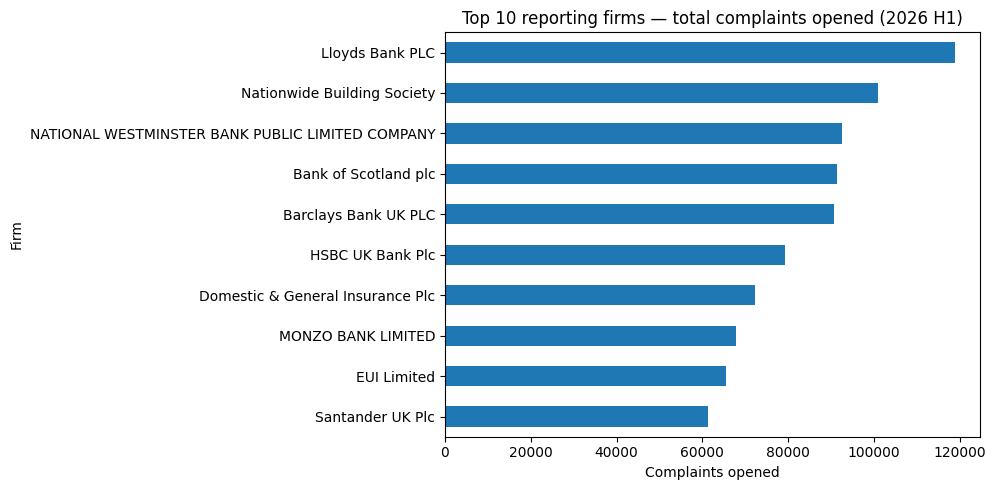

Top 10 share of reported total: 47.8%


In [58]:
latest = firm[firm["Semester"] == "2026 H1"].copy()
latest = latest[latest["Total opened"].notna()].copy()

# Grouping allows one ranking per firm name, if several records are present.
firm_latest = latest.groupby("Firm Name")["Total opened"].sum().sort_values(ascending=False)
firm_top10 = firm_latest.head(10)
display(firm_top10.to_frame("Total complaints opened"))

plt.figure(figsize=(10, 5))
firm_top10.sort_values().plot(kind="barh")
plt.title("Top 10 reporting firms — total complaints opened (2026 H1)")
plt.xlabel("Complaints opened")
plt.ylabel("Firm")
plt.tight_layout()
plt.show()

print("Top 10 share of reported total: {:.1f}%".format(firm_top10.sum() / firm_latest.sum() * 100))

## Step 2 — What product groups account for complaints within leading firms?
**Question:** For each Top 10 firm, how are *its complaints* split across the five groups?

**Output:** Stacked count bars and percentage mix table.

**How to interpret:** A firm dominated by Banking complaints may simply offer more banking accounts. The mix helps identify **where to investigate within that firm**, but it does not rank products by quality. `NaN` is shown as an absent category in the chart only; the raw data is unchanged.

Product-group share (%) within each Top 10 firm:


,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
Firm Name,,,,,
Lloyds Bank PLC,97.4,0.0,2.3,0.3,0.0
Nationwide Building Society,92.8,0.0,6.9,0.3,0.0
NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,93.5,0.0,5.9,0.1,0.5
Bank of Scotland plc,85.6,0.0,14.2,0.2,0.0
Barclays Bank UK PLC,93.8,0.0,5.9,0.3,0.0
HSBC UK Bank Plc,92.5,0.1,5.4,0.5,1.5
Domestic & General Insurance Plc,NaN,NaN,NaN,100.0,NaN
MONZO BANK LIMITED,99.6,0.1,NaN,0.0,0.2
EUI Limited,NaN,NaN,NaN,100.0,NaN


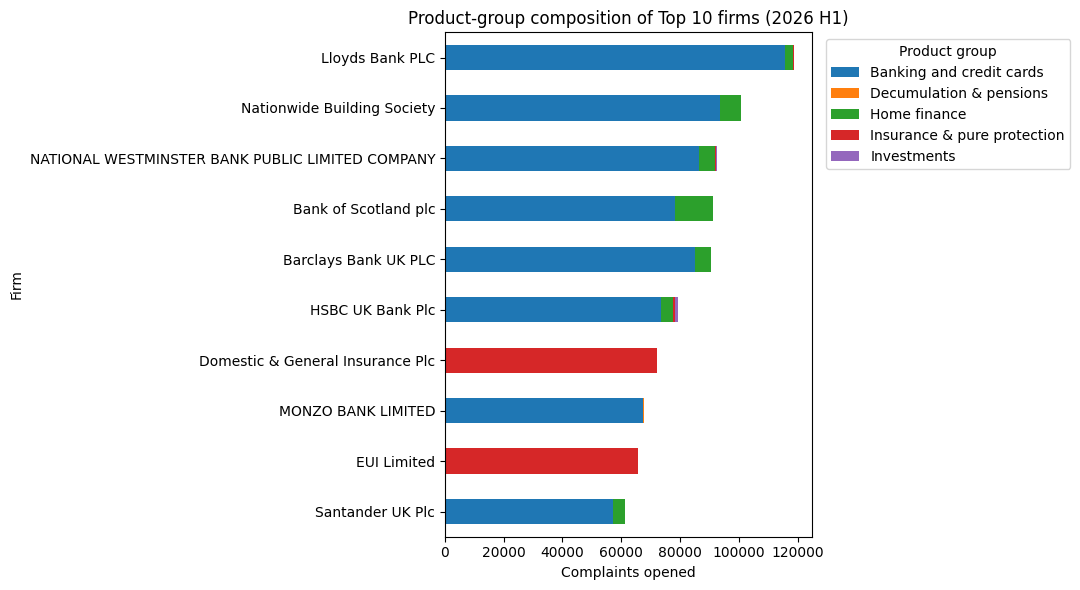

In [59]:
top_names = firm_top10.index.tolist()
latest_top = latest[latest["Firm Name"].isin(top_names)]
composition = latest_top.groupby("Firm Name")[product_cols].sum(min_count=1)
composition = composition.reindex(top_names)
firm_share = composition.div(composition.sum(axis=1), axis=0) * 100
print("Product-group share (%) within each Top 10 firm:")
display(firm_share.round(1))

composition.fillna(0).plot(kind="barh", stacked=True, figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Product-group composition of Top 10 firms (2026 H1)")
plt.xlabel("Complaints opened")
plt.ylabel("Firm")
plt.legend(title="Product group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 3 — Which firms lead within each product group?
**Question:** Within *each* of the five groups, which reporting firms have the largest complaint counts in 2026 H1?

**Output:** Five Top 5 charts generated automatically. **No `chosen_product` to edit.**

**How to interpret:** A firm absent from overall Top 10 can still be important within Investments or Home finance. These are **firm rankings within categories**, not detailed product-level EDA or customer-level complaint rates.


 Banking and credit cards


,Complaints opened
Firm Name,
Lloyds Bank PLC,115687.0
Nationwide Building Society,93640.0
NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,86498.0
Barclays Bank UK PLC,85021.0
Bank of Scotland plc,78145.0


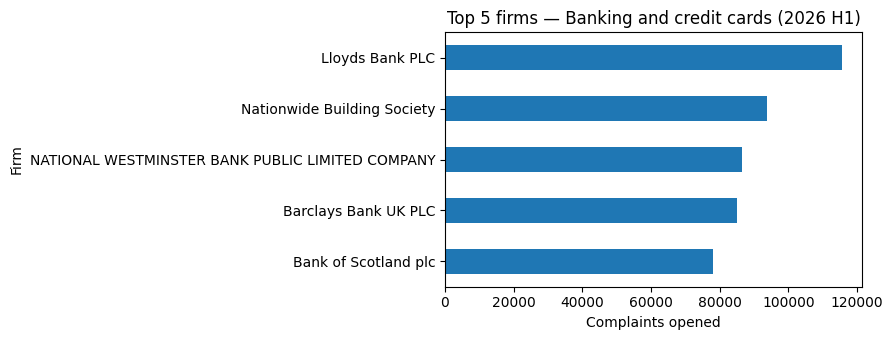


 Decumulation & pensions


,Complaints opened
Firm Name,
Aviva Administration Limited,20143.0
Phoenix Life Limited,11486.0
"ROYAL LONDON MUTUAL INSURANCE SOCIETY,LIMITED(THE)",6422.0
The Prudential Assurance Company Limited,5635.0
Scottish Equitable Plc,5207.0


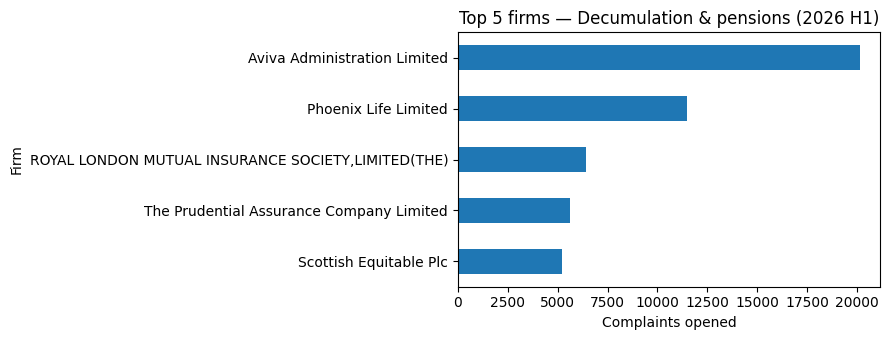


 Home finance


,Complaints opened
Firm Name,
Bank of Scotland plc,12934.0
Nationwide Building Society,6915.0
NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,5451.0
Barclays Bank UK PLC,5356.0
HSBC UK Bank Plc,4246.0


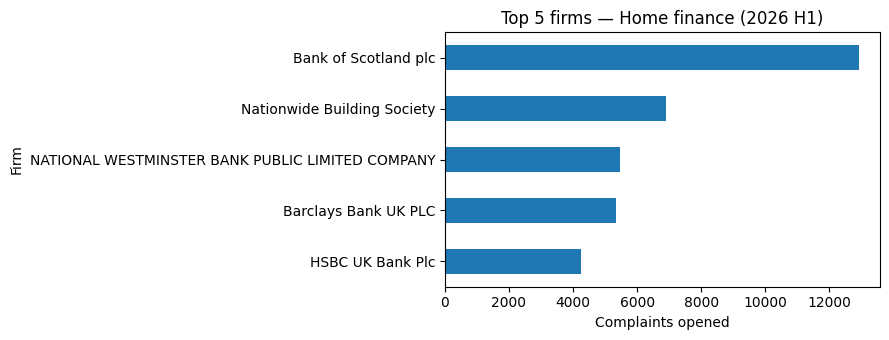


 Insurance & pure protection


,Complaints opened
Firm Name,
Domestic & General Insurance Plc,72314.0
EUI Limited,65577.0
Aviva Insurance Limited,54710.0
British Gas Services Limited,46797.0
U K Insurance Limited,37795.0


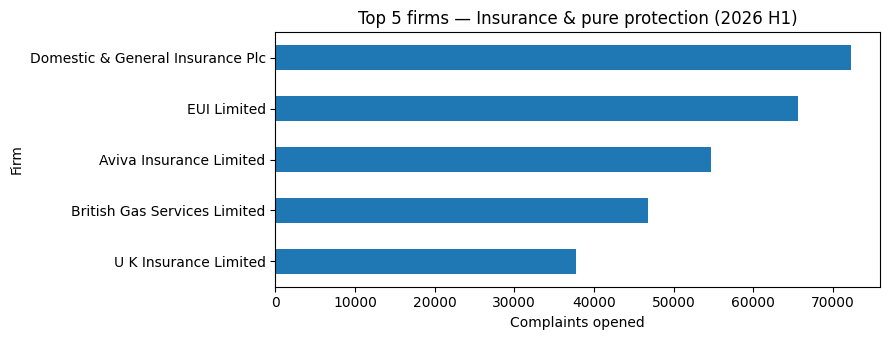


 Investments


,Complaints opened
Firm Name,
Hargreaves Lansdown Asset Management Limited,8328.0
Aviva Administration Limited,4088.0
Interactive Investor Services Limited,4069.0
Equiniti Financial Services Limited,3115.0
The Prudential Assurance Company Limited,2606.0


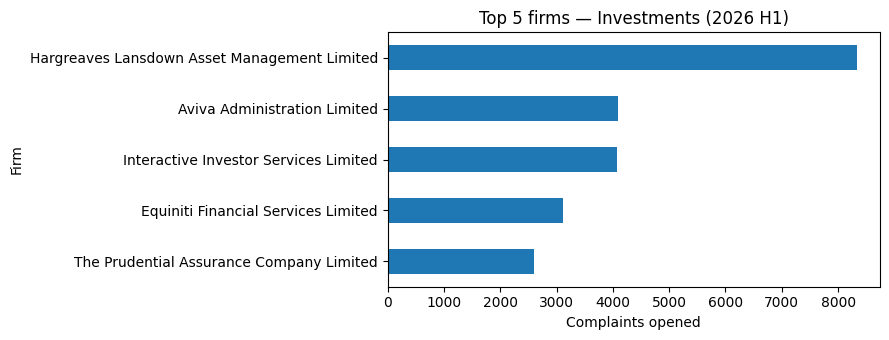

In [60]:
for product in product_cols:
    ranks = latest.groupby("Firm Name")[product].sum(min_count=1).dropna().sort_values(ascending=False).head(5)
    print("\n", product)
    display(ranks.to_frame("Complaints opened"))
    plt.figure(figsize=(9, 3.5))
    ranks.sort_values().plot(kind="barh")
    plt.title("Top 5 firms — " + product + " (2026 H1)")
    plt.xlabel("Complaints opened")
    plt.ylabel("Firm")
    plt.tight_layout()
    plt.show()

# Phase B — Comparable recent changes

## Step 4 — How complete is the firm's reporting history?
**Question:** Which firms have full, partial, or recently observed reporting histories?

**Output:** Coverage by semester and a count of firm names observed in all 9 periods.

**How to interpret:** A firm's first appearance in this published dataset is **not proof** it was founded then or had zero complaints previously. Firms may enter/leave publication coverage or change reporting arrangements. Full-history counts are a coverage screen, not automatic proof that reporting bases match.

,Observed firms
Semester,
2022 H1,213
2022 H2,212
2023 H1,232
2023 H2,233
2024 H1,229
2024 H2,220
2025 H1,218
2025 H2,219
2026 H1,226


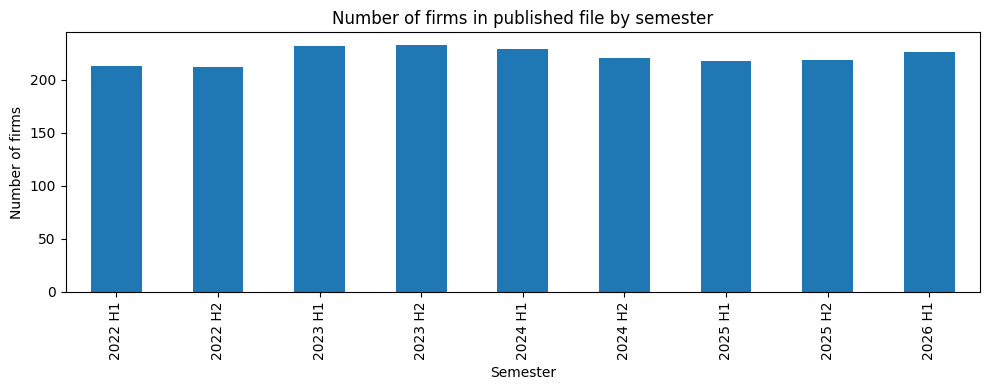

Firms observed in all 9 semesters: 112
Firms observed in fewer than 9 semesters: 268
First observed semester (selected later firms):


,First observed
Firm Name,
2GETHER INSURANCE LTD,2026 H1
ACORN INSURANCE AND FINANCIAL SERVICES LIMITED,2025 H2
ALLICA BANK LIMITED,2026 H1
ANIMAL FRIENDS INSURANCE SERVICES LIMITED,2025 H2
Admiral Financial Services Limited,2025 H1
Antares Insurance Company Limited,2025 H2
Arch Insurance (UK) Limited,2026 H1
Ascent Performance Group Limited,2025 H2
AutoProtect (MBI) Ltd,2025 H1


In [61]:
coverage = firm.groupby("Semester")["Firm Name"].nunique().reindex(semester_order)
display(coverage.to_frame("Observed firms"))

plt.figure(figsize=(10, 4))
coverage.plot(kind="bar")
plt.title("Number of firms in published file by semester")
plt.ylabel("Number of firms")
plt.xlabel("Semester")
plt.tight_layout()
plt.show()

firm_period_counts = firm.groupby("Firm Name")["Semester"].nunique()
print("Firms observed in all 9 semesters:", (firm_period_counts == 9).sum())
print("Firms observed in fewer than 9 semesters:", (firm_period_counts < 9).sum())

first_seen = firm.groupby("Firm Name")["Semester"].min()
print("First observed semester (selected later firms):")
display(first_seen[first_seen >= "2025 H1"].to_frame("First observed").head(15))

### Prepare a fair 2025 H1 vs 2026 H1 comparison
We keep only pairs with **one record per firm and semester**, the same firm group, the same joint-reporting label, and matching month/day reporting windows. For firm **total** change, the set of non-missing product groups must also be identical. For **each product group**, both values must be reported. This is a conservative comparability screen (not evidence that firm size was constant).

**How to interpret:** Excluded firms may still appear in current rankings; they are **not assumed to have zero complaints** in missing periods.

In [62]:
before = firm[firm["Semester"] == "2025 H1"].copy()
after = firm[firm["Semester"] == "2026 H1"].copy()

# Exclude ambiguous firm-semester records rather than choosing one automatically.
before = before[~before["Firm Name"].duplicated(keep=False)]
after = after[~after["Firm Name"].duplicated(keep=False)]

pairs = before.merge(after, on="Firm Name", suffixes=("_2025", "_2026"))

# Compare the month/day windows (e.g. Jan-Jun both years, or Oct-Mar both years).
period_2025 = pairs["Reporting period_2025"].str.replace(r"\d{4}-", "", regex=True)
period_2026 = pairs["Reporting period_2026"].str.replace(r"\d{4}-", "", regex=True)
pairs["Comparable reporting"] = (
    (period_2025 == period_2026)
    & (pairs["Firm Group_2025"] == pairs["Firm Group_2026"])
    & (pairs["Joint Reporting_2025"] == pairs["Joint Reporting_2026"])
)
print("Observed in both H1 periods:", len(pairs))
print("Comparable reporting basis:", pairs["Comparable reporting"].sum())
pairs = pairs[pairs["Comparable reporting"]].copy()

# Require identical observed group coverage before comparing all-product totals.
pairs["Same product coverage"] = True
for product in product_cols:
    pairs["Same product coverage"] = pairs["Same product coverage"] & (
        pairs[product + "_2025"].notna() == pairs[product + "_2026"].notna()
    )
total_pairs = pairs[pairs["Same product coverage"]].copy()
print("Comparable firms for all-group total:", len(total_pairs))

Observed in both H1 periods: 174
Comparable reporting basis: 91
Comparable firms for all-group total: 84


## Step 5 — Which firms have the largest YoY change?
**Question:** Among comparable reporting firms, whose **total complaint count** changed most between 2025 H1 and 2026 H1?

**Output:** Largest absolute increases/decreases, plus percentage growth for firms with positive 2025 baselines.

**How to interpret:** Use absolute change for workload, % change for scale relative to last year. Very high % from a small baseline can mislead. Do **not** call it a change in complaint *rate*.

Largest absolute increases:


,Firm Name,Total opened_2025,Total opened_2026,Change,YoY %
100,Lloyds Bank PLC,81403.0,118762.0,37359.0,45.893886
31,Bank of Scotland plc,77714.0,91326.0,13612.0,17.515506
24,Aviva Insurance Limited,48979.0,54710.0,5731.0,11.700933
75,Hastings Insurance Services Limited,18123.0,23151.0,5028.0,27.743751
74,Hargreaves Lansdown Asset Management Limited,6639.0,10892.0,4253.0,64.060853
81,Howserv Limited,2358.0,4693.0,2335.0,99.024597
6,Ageas Retail Limited,912.0,3062.0,2150.0,235.745614
89,Interactive Investor Services Limited,2505.0,4480.0,1975.0,78.842315
28,AXA Insurance UK Plc,16910.0,18717.0,1807.0,10.685985
141,Society of Lloyd's,4972.0,6239.0,1267.0,25.482703


Largest absolute decreases:


,Firm Name,Total opened_2025,Total opened_2026,Change,YoY %
62,EUI Limited,70326.0,65577.0,-4749.0,-6.752837
135,SCOTTISH WIDOWS LIMITED,10846.0,6352.0,-4494.0,-41.434630
36,BUPA Insurance Services Limited,31133.0,27891.0,-3242.0,-10.413388
133,Scottish Equitable Plc,7901.0,5331.0,-2570.0,-32.527528
20,Atlanta Insurance Intermediaries Limited,9569.0,7847.0,-1722.0,-17.995611
110,NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,94120.0,92548.0,-1572.0,-1.670208
131,Saga Services Limited,8353.0,6785.0,-1568.0,-18.771699
114,One Call Insurance Services Limited,3098.0,1973.0,-1125.0,-36.313751
132,Santander UK Plc,62386.0,61365.0,-1021.0,-1.636585
144,St. James's Place Wealth Management Plc,5511.0,4495.0,-1016.0,-18.435856


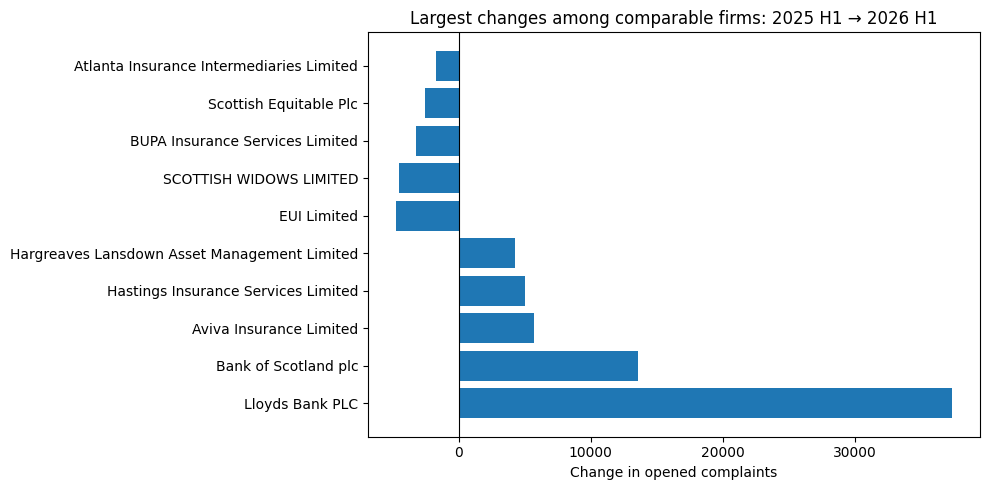

In [63]:
total_pairs["Change"] = total_pairs["Total opened_2026"] - total_pairs["Total opened_2025"]
total_pairs["YoY %"] = (
    total_pairs["Change"] / total_pairs["Total opened_2025"].replace(0, float("nan")) * 100
)
change_table = total_pairs[["Firm Name", "Total opened_2025", "Total opened_2026", "Change", "YoY %"]].copy()
print("Largest absolute increases:")
display(change_table.sort_values("Change", ascending=False).head(10))
print("Largest absolute decreases:")
display(change_table.sort_values("Change").head(10))

big_movers = pd.concat([change_table.nlargest(5, "Change"), change_table.nsmallest(5, "Change")])
plt.figure(figsize=(10, 5))
plt.barh(big_movers["Firm Name"], big_movers["Change"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest changes among comparable firms: 2025 H1 → 2026 H1")
plt.xlabel("Change in opened complaints")
plt.tight_layout()
plt.show()

## Step 6 — Which product groups explain the firm-level changes?
**Question:** For the largest positive and negative firm movers, how did counts change in each of the five groups?

**Output:** Product-group change table and stacked positive/negative changes across selected firms.

**How to interpret:** A firm can have an almost unchanged total even if one group rose and another fell. This identifies *which category changed within the firm*, not why customers complained. Missing at either endpoint remains missing.

Change by product group (NaN means not comparable for that category):


,Banking and credit cards,Decumulation & pensions,Home finance,Insurance & pure protection,Investments
Firm Name,,,,,
Atlanta Insurance Intermediaries Limited,NaN,NaN,NaN,-1722.0,NaN
Aviva Insurance Limited,NaN,NaN,NaN,5731.0,NaN
Bank of Scotland plc,12808.0,-3.0,814.0,6.0,-13.0
BUPA Insurance Services Limited,NaN,NaN,NaN,-3242.0,NaN
EUI Limited,NaN,NaN,NaN,-4749.0,NaN
Hargreaves Lansdown Asset Management Limited,NaN,626.0,NaN,NaN,3627.0
Hastings Insurance Services Limited,NaN,NaN,NaN,5028.0,NaN
Lloyds Bank PLC,37568.0,-12.0,-166.0,-11.0,-20.0
Scottish Equitable Plc,NaN,-2355.0,NaN,-3.0,-212.0


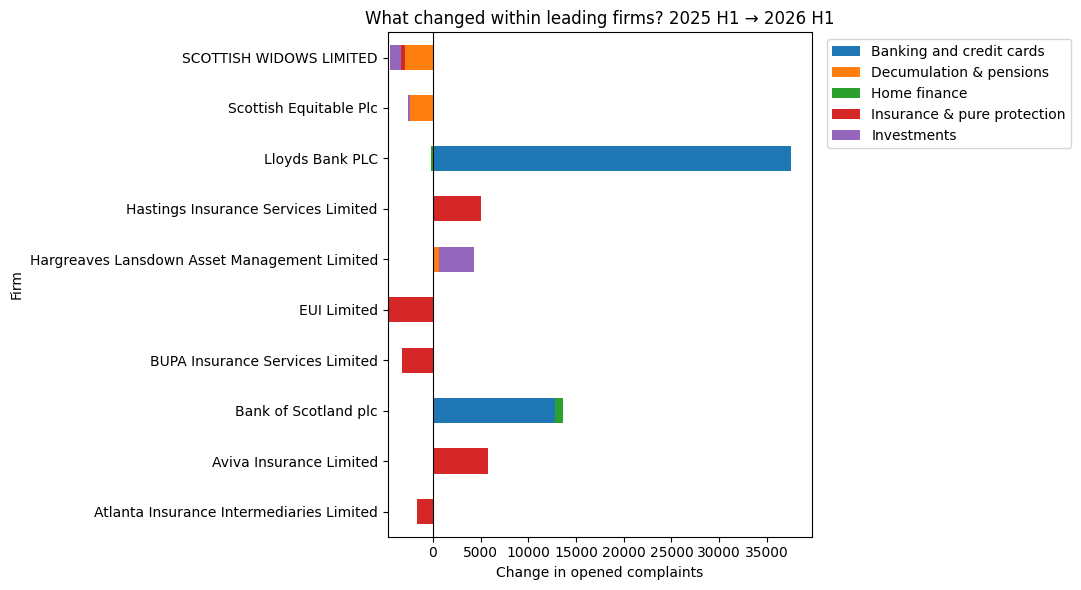

In [64]:
mover_names = big_movers["Firm Name"].tolist()
for product in product_cols:
    pairs[product + " change"] = pairs[product + "_2026"] - pairs[product + "_2025"]

mover_changes = pairs[pairs["Firm Name"].isin(mover_names)].set_index("Firm Name")
changes_by_group = mover_changes[[p + " change" for p in product_cols]]
changes_by_group.columns = product_cols
print("Change by product group (NaN means not comparable for that category):")
display(changes_by_group.round(0))

# Plot positive and negative values separately so opposing changes are visible.
plot_change = changes_by_group.fillna(0)
positive = plot_change.clip(lower=0)
negative = plot_change.clip(upper=0)
ax = positive.plot(kind="barh", stacked=True, figsize=(11, 6), legend=False)
negative.plot(kind="barh", stacked=True, ax=ax, legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("What changed within leading firms? 2025 H1 → 2026 H1")
plt.xlabel("Change in opened complaints")
plt.ylabel("Firm")
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[:len(product_cols)], product_cols, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Phase C — Change drivers and longer-term patterns

## Step 7 — Is the change widespread or concentrated among a few firms?
**Question:** Within **each of the five product groups**, how many comparable firms increased or decreased, and which firms contributed the largest changes?

**Output:** A table for every group, plus automatic Top 5 increases/decreases. No manual product selection.

**How to interpret:** A group total may rise even if most firms fall, when a few firms rise sharply. This is a **matched-firm finding**, not necessarily an industry-wide trend. Negative changes offset positive contributions.

In [65]:
driver_summary = []
for product in product_cols:
    group_pair = pairs[["Firm Name", product + "_2025", product + "_2026"]].dropna().copy()
    group_pair["Change"] = group_pair[product + "_2026"] - group_pair[product + "_2025"]
    driver_summary.append({
        "Product group": product,
        "Matched firms": len(group_pair),
        "Increasing": (group_pair["Change"] > 0).sum(),
        "Decreasing": (group_pair["Change"] < 0).sum(),
        "Unchanged": (group_pair["Change"] == 0).sum(),
        "Net change": group_pair["Change"].sum()
    })
    print("\nPRODUCT GROUP:", product)
    print("Largest increases:")
    display(group_pair.nlargest(5, "Change")[["Firm Name", "Change"]])
    print("Largest decreases:")
    display(group_pair.nsmallest(5, "Change")[["Firm Name", "Change"]])

summary_drivers = pd.DataFrame(driver_summary)
display(summary_drivers)


PRODUCT GROUP: Banking and credit cards
Largest increases:


,Firm Name,Change
100,Lloyds Bank PLC,37568.0
31,Bank of Scotland plc,12808.0
90,J.P. Morgan Europe Limited,1278.0
39,Capital One (Europe) plc,1094.0
156,Trading 212 UK Limited,385.0


Largest decreases:


,Firm Name,Change
103,MBNA Limited,-930.0
140,Skipton Building Society,-814.0
93,Leeds Building Society,-688.0
110,NATIONAL WESTMINSTER BANK PUBLIC LIMITED COMPANY,-673.0
30,Bank of Ireland (UK) Plc,-469.0



PRODUCT GROUP: Decumulation & pensions
Largest increases:


,Firm Name,Change
74,Hargreaves Lansdown Asset Management Limited,626.0
124,Quilter Life & Pensions Limited,206.0
89,Interactive Investor Services Limited,131.0
57,Embark Investment Services Limited,104.0
9,AJ Bell Securities Limited,92.0


... (11 outputs left out)

,Firm Name,Change
74,Hargreaves Lansdown Asset Management Limited,3627.0
89,Interactive Investor Services Limited,1844.0
156,Trading 212 UK Limited,1237.0
59,Equiniti Financial Services Limited,782.0
65,Family Assurance Friendly Society Limited,303.0


Largest decreases:


,Firm Name,Change
135,SCOTTISH WIDOWS LIMITED,-1132.0
134,Scottish Friendly Assurance Society Limited,-483.0
144,St. James's Place Wealth Management Plc,-286.0
47,Cofunds Limited,-269.0
133,Scottish Equitable Plc,-212.0


,Product group,Matched firms,Increasing,Decreasing,Unchanged,Net change
0,Banking and credit cards,32,13,13,6,49157.0
1,Decumulation & pensions,28,12,12,4,-5792.0
2,Home finance,30,11,13,6,-2094.0
3,Insurance & pure protection,67,36,26,5,10066.0
4,Investments,30,15,12,3,6111.0


## Step 8 — Are higher complaint counts persistent or short-lived?
**Question:** Among firms reporting throughout all nine semesters, what do the complaint histories look like?

**Output:** Line chart for selected leading firms that pass a history/consistency screen. Gaps are **never filled with zero**.

**How to interpret:** A spike in only one period differs from a multi-year pattern. This screen requires one row in each period, stable `Firm Group`/`Joint Reporting`, and consistent reporting **month/day windows within each H1 or H2** over time. It is restrictive, but does not guarantee unchanged business mix or customer base.

Firms with shorter histories are still included in Steps 1–3, but are not shown here as full nine-period trends.

Firms with nine consistent reporting records: 18


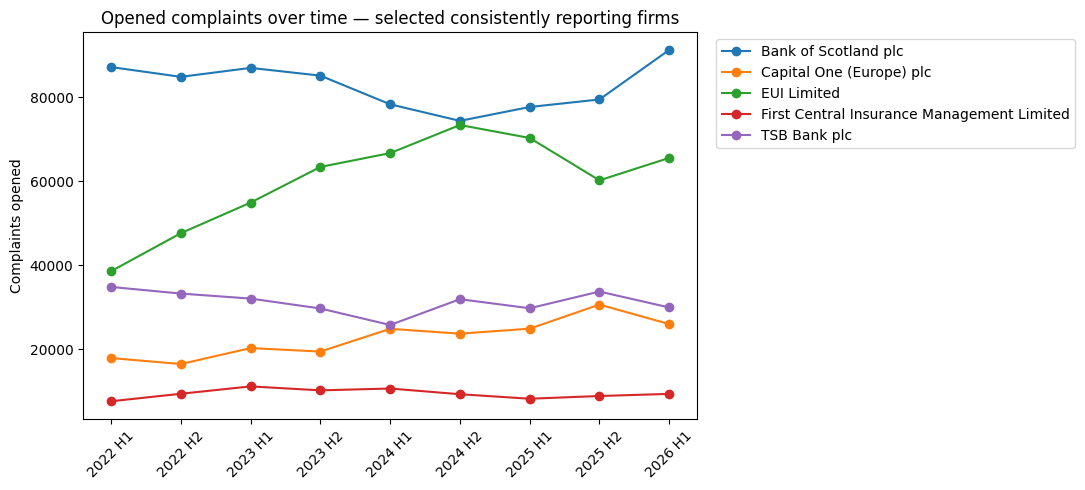

In [66]:
# One row in every semester, and no duplicate firm-semester records.
count_by_firm = firm.groupby("Firm Name")["Semester"].nunique()
row_counts = firm.groupby("Firm Name").size()
full_names = count_by_firm[count_by_firm == 9].index
full = firm[firm["Firm Name"].isin(full_names)].copy()
full = full[full["Firm Name"].isin(row_counts[row_counts == 9].index)]

# Retain firms with stable reporting group, joint flag and month/day windows.
full["Window"] = full["Reporting period"].str.replace(r"\d{4}-", "", regex=True)
stable = full.groupby("Firm Name").agg({
    "Firm Group": "nunique",
    "Joint Reporting": "nunique",
    "Window": "nunique"
})
# Two stable reporting windows are expected: one for H1 and one for H2.
full["Half"] = full["Semester"].str[-2:]
window_counts = full.groupby(["Firm Name", "Half"])["Window"].nunique()
window_ok = window_counts.groupby("Firm Name").max() == 1
stable_names = stable[(stable["Firm Group"] == 1) & (stable["Joint Reporting"] == 1)].index
stable_names = stable_names.intersection(window_ok[window_ok].index)
full = full[full["Firm Name"].isin(stable_names)]

# To compare total opened complaints, require the same reported product categories in all periods.
coverage_ok = pd.Series(True, index=full["Firm Name"].unique())
for product in product_cols:
    count_nonmissing = full.groupby("Firm Name")[product].count()
    coverage_ok = coverage_ok & ((count_nonmissing == 0) | (count_nonmissing == 9))
full = full[full["Firm Name"].isin(coverage_ok[coverage_ok].index)]
print("Firms with nine consistent reporting records:", full["Firm Name"].nunique())

leaders = full[full["Semester"] == "2026 H1"].nlargest(5, "Total opened")["Firm Name"].tolist()
firm_trend = full[full["Firm Name"].isin(leaders)].pivot(index="Semester", columns="Firm Name", values="Total opened")
firm_trend = firm_trend.reindex(semester_order)

plt.figure(figsize=(11, 5))
for name in firm_trend.columns:
    plt.plot(firm_trend.index, firm_trend[name], marker="o", label=name)
plt.xticks(rotation=45)
plt.ylabel("Complaints opened")
plt.title("Opened complaints over time — selected consistently reporting firms")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 9 — How much does reporting coverage change the observed totals?
**Question:** Does the all-firm total move in the same direction as the matched-firm total?

**Output:** A short comparison table showing (a) all observed firms, (b) comparable firms with unchanged group coverage, and (c) the unmatched remainder.

**How to interpret:** A difference between series reflects sample/reporting coverage **and potentially reporting-basis changes**. It does **not** measure how much business was gained/lost in the wider market. The unmatched remainder cannot be called new firms or new complaints.

In [67]:
all_2025 = before["Total opened"].sum()
all_2026 = after["Total opened"].sum()
matched_2025 = total_pairs["Total opened_2025"].sum()
matched_2026 = total_pairs["Total opened_2026"].sum()

firm_comparison = pd.DataFrame({
    "2025 H1": [all_2025, matched_2025, all_2025 - matched_2025],
    "2026 H1": [all_2026, matched_2026, all_2026 - matched_2026]
}, index=["All observed firm records", "Comparable matched firms", "Remainder outside matched sample"])
firm_comparison["Change"] = firm_comparison["2026 H1"] - firm_comparison["2025 H1"]
display(firm_comparison)

print("Comparable matched firms:", len(total_pairs))
print("All observed firms: 2025 H1 =", before["Firm Name"].nunique(), "; 2026 H1 =", after["Firm Name"].nunique())
print("Interpretation: the remainder is affected by coverage and/or reporting comparability; it is not a causal explanation.")

,2025 H1,2026 H1,Change
All observed firm records,1740222.0,1757473.0,17251.0
Comparable matched firms,786807.0,841752.0,54945.0
Remainder outside matched sample,953415.0,915721.0,-37694.0


Comparable matched firms: 84
All observed firms: 2025 H1 = 218 ; 2026 H1 = 226
Interpretation: the remainder is affected by coverage and/or reporting comparability; it is not a causal explanation.


# Wrap-up — Interpretation and business implications

Use the results above to write **Observation → Deeper investigation → Business implication**.

| Analysis | What you may say | What you must NOT infer |
|---|---|---|
| Step 1: current firm ranking | Largest volumes in the published firm sample | Worst service or highest complaint rate |
| Step 2: firm composition | Which categories account for each firm's reported complaints | Specific causes (e.g., bad app UX) |
| Step 3: group-specific leaders | Which firms dominate counts in a category | Products are equally sized across firms |
| Step 4: coverage | Which firms/semesters are observed | Missing means zero, or newly observed means new firm |
| Step 5: matched YoY | Which comparable firms have biggest count changes | Increase implies declining service quality |
| Step 6: within-firm drivers | Which groups explain each firm's count changes | Why those group counts changed |
| Step 7: breadth vs concentration | Whether changes occur across many matched firms | Entire UK industry trend |
| Step 8: long-term firms | Persistent count patterns for a restricted panel | Firm size / mix stayed constant |
| Step 9: sample coverage | Sensitivity of totals to reporting coverage | Causal contribution of new firms to market growth |

**Practical next step:** Choose 2–3 firms with high current counts and/or large comparable increases, then investigate firm size, product portfolios, business changes and (if available) more granular complaints reason data. The separate aggregate product EDA can provide context, but its product trends are not necessarily identical to this published firm-level sample.

**Key limitation:** All analysis here uses counts of `Opened`. It does not answer the original *complaint rates* research question without an appropriate denominator.

## Export summary tables (optional)
Save tables locally from Colab to share with the group. This does not change the source file in Drive.

In [68]:
firm_top10.to_csv("firm_top10_2026H1.csv")
firm_share.to_csv("firm_top10_product_mix_percent.csv")
change_table.to_csv("firm_matched_yoy_change.csv", index=False)
summary_drivers.to_csv("firm_product_group_drivers.csv", index=False)
firm_comparison.to_csv("firm_reporting_coverage_comparison.csv")
print("Saved 5 summary CSV files in this Colab session.")

Saved 5 summary CSV files in this Colab session.


---

## Sharing and reproducibility notes

- **For the person maintaining the data:** set `REBUILD_CLEANED_DATA = True` only when you need to regenerate the two cleaned CSVs from the Excel sources. This overwrites the two filenames in Drive.
- **For other team members:** keep `REBUILD_CLEANED_DATA = False`; they only need access to the shared folder and both cleaned CSVs. Using **Runtime → Run all** ensures every plot uses the current files.
- The firm-level section's five *optional summary exports* retain the source notebook's behaviour: they save to the current Colab session, not to the shared Drive folder. Save/move them if the group wants to share those results.
- **Missing values:** blank cells in CSVs are read by pandas as `NaN`; do not recode them as zero without a defensible, documented reason.
- The aggregate product-level and reported firm-level files are **different reporting datasets**. Do not assume their totals should match.
